In [1]:
from pathlib import Path
import os, re, json, subprocess, time, warnings, gc
import numpy as np
import pandas as pd
from scipy.sparse import hstack
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from IPython.display import display
warnings.filterwarnings("ignore")

NOTEBOOK_DIR = Path.cwd()

TRAIN_PATH = NOTEBOOK_DIR / 'train.csv'
TEST_PATH = NOTEBOOK_DIR / 'test.csv'

ROOT = NOTEBOOK_DIR / 'output'
ROOT.mkdir(parents=True, exist_ok=True)

if not TRAIN_PATH.exists():
    raise FileNotFoundError(
        f'train.csv tidak ditemukan di {NOTEBOOK_DIR}.\n'
        f'Pastikan file train.csv ada di folder yang sama dengan notebook ini.'
    )

print('NOTEBOOK_DIR:', NOTEBOOK_DIR)
print('TRAIN_PATH:', TRAIN_PATH)
train_raw = pd.read_csv(TRAIN_PATH)
print('Official train shape:', train_raw.shape)
display(train_raw.head(3))

if TEST_PATH.exists():
    print('\nTEST_PATH:', TEST_PATH)
    test_raw = pd.read_csv(TEST_PATH)
    print('Official test shape:', test_raw.shape)
else:
    print('\ntest.csv tidak ditemukan - submission akan dilewati.')
    test_raw = None

NOTEBOOK_DIR: d:\Mode Kompe\DIMAS TI
TRAIN_PATH: d:\Mode Kompe\DIMAS TI\train.csv
Official train shape: (36696, 7)


,row_id,QuestionId,QuestionText,MC_Answer,StudentExplanation,Category,Misconception
0,0,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),0ne third is equal to tree nineth,True_Correct,NaN
1,1,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),1 / 3 because 6 over 9 is 2 thirds and 1 third...,True_Correct,NaN
2,2,31772,What fraction of the shape is not shaded? Give...,\( \frac{1}{3} \),"1 3rd is half of 3 6th, so it is simplee to un...",True_Neither,NaN



TEST_PATH: d:\Mode Kompe\DIMAS TI\test.csv
Official test shape: (3, 5)


In [2]:
MIME_URL = 'https://github.com/scrosseye/mime_dataset.git'
MIME_DIR = ROOT/'mime_dataset'

# Clone butuh internet. Jika Internet Kaggle nonaktif, langkah audit MIME dilewati
# (tidak memengaruhi training/CV pada train.csv resmi).
if not MIME_DIR.exists():
    try:
        subprocess.run(['git','clone','--depth','1',MIME_URL,str(MIME_DIR)],
                       check=True, capture_output=True, text=True, timeout=120)
    except Exception as e:
        print('Clone MIME dilewati (internet nonaktif / repo tidak dapat diakses):', type(e).__name__)

TABULAR_EXTS = {'.csv','.tsv','.parquet','.jsonl','.json','.xlsx'}
files = []
if MIME_DIR.exists():
    for p in MIME_DIR.rglob('*'):
        if p.is_file() and '.git' not in p.parts and p.suffix.lower() in TABULAR_EXTS:
            files.append({'path':str(p.relative_to(MIME_DIR)), 'bytes':p.stat().st_size})
file_index = pd.DataFrame(files, columns=['path','bytes']).sort_values('path').reset_index(drop=True)
display(file_index)
print('Do not assume every labelled file is safe for training. Files named test, benchmark, holdout, private, eval, or validation are not training augmentation by default.')

,path,bytes
0,dataset_minus_700_for_github.csv,13354420


Do not assume every labelled file is safe for training. Files named test, benchmark, holdout, private, eval, or validation are not training augmentation by default.


In [3]:
def read_table(path):
    p = Path(path)
    if p.suffix.lower()=='.csv': return pd.read_csv(p, low_memory=False)
    if p.suffix.lower()=='.tsv': return pd.read_csv(p, sep='\t', low_memory=False)
    if p.suffix.lower()=='.parquet': return pd.read_parquet(p)
    if p.suffix.lower()=='.jsonl': return pd.read_json(p, lines=True)
    if p.suffix.lower()=='.json':
        try: return pd.read_json(p, lines=True)
        except ValueError: return pd.read_json(p)
    if p.suffix.lower()=='.xlsx': return pd.read_excel(p)
    raise ValueError(p.suffix)

EXCLUDE_TOKENS = ('test','testing','benchmark','holdout','heldout','private','eval','evaluation','validation','valid')
def looks_like_train(path):
    s = str(path).lower()
    return 'train' in s and not any(t in s for t in EXCLUDE_TOKENS)

candidate_paths = [MIME_DIR/row['path'] for _,row in file_index.iterrows() if looks_like_train(row['path'])]
print('Training-name candidates:', [str(p.relative_to(MIME_DIR)) for p in candidate_paths])
for p in candidate_paths:
    try:
        tmp = read_table(p)
        print('\nFILE:', p.relative_to(MIME_DIR), '| shape:', tmp.shape, '| columns:', list(tmp.columns))
        display(tmp.head(2))
    except Exception as e:
        print('Could not read', p, repr(e))

# If the repository uses different split names, set MIME_TRAIN_PATH manually after reviewing file_index.
MIME_TRAIN_PATH = None  # Example: MIME_DIR/'data'/'train.csv'
print('Set MIME_TRAIN_PATH only after verifying the file is a training split in the repository README.')

Training-name candidates: []
Set MIME_TRAIN_PATH only after verifying the file is a training split in the repository README.


In [4]:
def norm_text(x):
    if pd.isna(x): return ''
    return re.sub(r'\s+',' ',str(x).replace('\u200b',' ').replace('\ufeff',' ')).strip().lower()

def find_col(df, aliases):
    lookup = {re.sub(r'[^a-z0-9]+','',str(c).lower()):c for c in df.columns}
    for a in aliases:
        key = re.sub(r'[^a-z0-9]+','',a.lower())
        if key in lookup: return lookup[key]
    return None

def audit_mime_file(path, official):
    ext = read_table(path)
    e_exp = find_col(ext,['StudentExplanation','student_explanation','explanation','response','text'])
    o_exp = find_col(official,['StudentExplanation','student_explanation','explanation'])
    if not e_exp or not o_exp:
        return {'path':str(path),'shape':ext.shape,'columns':list(ext.columns),'error':'Could not map explanation column'}
    e = ext.copy(); o = official.copy()
    e['__exp_norm'] = e[e_exp].map(norm_text); o['__exp_norm'] = o[o_exp].map(norm_text)
    summary = {'path':str(path),'rows':len(e),'columns':list(ext.columns),
               'exact_explanation_overlap_rows':int(e['__exp_norm'].isin(set(o['__exp_norm'])).sum()),
               'duplicate_explanation_rows_within_file':int(e['__exp_norm'].duplicated().sum()),
               'possible_provenance_columns':[c for c in ext.columns if any(t in str(c).lower() for t in ['synthetic','augment','source','origin','parent','original_id'])]}
    q_e=find_col(e,['QuestionId','question_id','qid']); q_o=find_col(o,['QuestionId','question_id','qid'])
    a_e=find_col(e,['MC_Answer','mc_answer','answer','selected_answer']); a_o=find_col(o,['MC_Answer','mc_answer','answer','selected_answer'])
    if q_e and q_o and a_e and a_o:
        e['__key']=e[q_e].astype(str)+'||'+e[a_e].astype(str)+'||'+e['__exp_norm']
        o['__key']=o[q_o].astype(str)+'||'+o[a_o].astype(str)+'||'+o['__exp_norm']
        summary['exact_question_answer_explanation_overlap_rows']=int(e['__key'].isin(set(o['__key'])).sum())
    return summary

if 'train_raw' in globals() and MIME_TRAIN_PATH is not None:
    MIME_TRAIN_PATH = Path(MIME_TRAIN_PATH)
    if not MIME_TRAIN_PATH.exists(): raise FileNotFoundError(MIME_TRAIN_PATH)
    if not looks_like_train(str(MIME_TRAIN_PATH.relative_to(MIME_DIR))):
        raise ValueError('Selected file name/path is not clearly training-only. Re-check split provenance.')
    mime_audit = audit_mime_file(MIME_TRAIN_PATH, train_raw)
    print(json.dumps(mime_audit, indent=2, default=str))
else:
    print('Audit not run yet. Review file_index, then set MIME_TRAIN_PATH to an explicitly verified training file and rerun this cell.')

Audit not run yet. Review file_index, then set MIME_TRAIN_PATH to an explicitly verified training file and rerun this cell.


In [5]:
def target_full(df):
    mis=df['Misconception'].fillna('NA').astype(str).str.strip().replace({'':'NA','nan':'NA','None':'NA'})
    mis=mis.where(df['Category'].astype(str).str.endswith('_Misconception'),'NA')
    return (df['Category'].astype(str).str.strip()+':'+mis).to_numpy(dtype=str)

def target_reduced(df):
    out=[]
    for cat,mis in zip(df['Category'].astype(str),df['Misconception']):
        if cat.endswith('_Misconception'):
            mis='' if pd.isna(mis) else str(mis).strip()
            if mis.lower()=='wrong_fraction': mis='Wrong_Fraction'
            out.append(mis)
        elif cat.endswith('_Correct'): out.append('Correct')
        else: out.append('Neither')
    return np.asarray(out,dtype=str)

def text_context(df):
    q=df['QuestionText'].fillna('').astype(str); a=df['MC_Answer'].fillna('').astype(str); e=df['StudentExplanation'].fillna('').astype(str)
    return ('question: '+q+' answer: '+a+' explanation: '+e).to_numpy(dtype=str)

def answer_key_fit(df):
    tmp=df[['QuestionId','MC_Answer','Category']].copy()
    tmp['true']=tmp['Category'].astype(str).str.startswith('True_').astype(int)
    agg=tmp.groupby(['QuestionId','MC_Answer'])['true'].agg(['mean','sum','count']).reset_index()
    agg=agg.sort_values(['QuestionId','mean','count','sum'],ascending=[True,False,False,False])
    return agg.drop_duplicates('QuestionId').set_index('QuestionId')['MC_Answer'].to_dict()

def score_map3(y, pred):
    y=np.asarray(y,dtype=str); pred=np.asarray(pred,dtype=str); rr=np.zeros(len(y),float)
    for rank in range(min(3,pred.shape[1])):
        hit=(pred[:,rank]==y)&(rr==0); rr[hit]=1/(rank+1)
    return {'MAP@3':float(rr.mean()),'Top1 Accuracy':float((pred[:,0]==y).mean()),'Hit@3':float((pred==y[:,None]).any(axis=1).mean())}

def run_official_cv(df, qa_weight=0.5, tol=0.1):
    df=df.copy()
    for c in ['QuestionText','MC_Answer','StudentExplanation']:
        df[c]=df[c].fillna('').astype(str).str.replace(r'\s+',' ',regex=True).str.strip()
    yfull=target_full(df); yred=target_reduced(df)
    groups=df['StudentExplanation'].map(norm_text).to_numpy()
    cv=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=42)
    rows=[]
    for fold,(ti,vi) in enumerate(cv.split(df,df['Category'].astype(str),groups=groups),1):
        tr=df.iloc[ti].reset_index(drop=True); va=df.iloc[vi].reset_index(drop=True)

        # Cek kebocoran berdasarkan grup penjelasan siswa (bukan QuestionId).
        # Overlap QuestionId antar-fold itu wajar karena soal yang sama
        # juga muncul di data uji dan dipakai sebagai fitur.
        train_groups = set(groups[ti])
        valid_groups = set(groups[vi])
        overlap = train_groups.intersection(valid_groups)

        print(
            f"Fold {fold}: "
            f"train={len(tr)} baris, validasi={len(va)} baris, "
            f"overlap grup penjelasan={len(overlap)}; "
            f"soal train={tr['QuestionId'].nunique()}, soal validasi={va['QuestionId'].nunique()}"
        )

        assert len(overlap) == 0, (
            f"Ada penjelasan yang bocor antar-fold: {len(overlap)} grup"
        )

        word=TfidfVectorizer(ngram_range=(1,2),min_df=2,max_df=.995,sublinear_tf=True,strip_accents='unicode',token_pattern=r'(?u)\b\w+\b',max_features=30000,dtype=np.float32)
        Xwtr=word.fit_transform(text_context(tr)); Xwva=word.transform(text_context(va))
        char=TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),min_df=2,max_df=.999,sublinear_tf=True,max_features=5000,dtype=np.float32)
        Xctr=char.fit_transform(tr['StudentExplanation']); Xcva=char.transform(va['StudentExplanation'])
        qid=OneHotEncoder(handle_unknown='ignore',dtype=np.float32)
        Xqtr=qid.fit_transform(tr[['QuestionId']].astype(str)); Xqva=qid.transform(va[['QuestionId']].astype(str))
        qa=OneHotEncoder(handle_unknown='ignore',dtype=np.float32)
        Xqatr=qa.fit_transform((tr.QuestionId.astype(str)+'|||'+tr.MC_Answer).to_frame('qa'))
        Xqava=qa.transform((va.QuestionId.astype(str)+'|||'+va.MC_Answer).to_frame('qa'))
        Xtr=hstack([Xwtr,Xctr*0.5,Xqtr*0.35,Xqatr*qa_weight],format='csr',dtype=np.float32)
        Xva=hstack([Xwva,Xcva*0.5,Xqva*0.35,Xqava*qa_weight],format='csr',dtype=np.float32)
        for mat in (Xtr,Xva): mat.sum_duplicates(); mat.sort_indices()
        model=LogisticRegression(C=1.0,solver='saga',max_iter=100,tol=tol,random_state=42)
        t0=time.time(); model.fit(Xtr,yred[ti]); fit_seconds=time.time()-t0
        prob=model.predict_proba(Xva); ix=np.argsort(-prob,axis=1,kind='mergesort')[:,:3]; red=np.asarray(model.classes_)[ix]
        key=answer_key_fit(tr); prefixes=np.array(['True' if q in key and key[q]==a else 'False' for q,a in zip(va.QuestionId,va.MC_Answer)])
        variants={q:g['Misconception'].value_counts().idxmax() for q,g in tr.loc[tr['Misconception'].fillna('').str.lower().eq('wrong_fraction')].groupby('QuestionId')}
        qids=va.QuestionId.to_numpy(); top=np.empty(red.shape,dtype=object)
        for i in range(len(va)):
            for j in range(3):
                lbl=red[i,j]
                if lbl=='Correct': out=f'{prefixes[i]}_Correct:NA'
                elif lbl=='Neither': out=f'{prefixes[i]}_Neither:NA'
                else:
                    m=variants.get(qids[i],'Wrong_Fraction') if lbl=='Wrong_Fraction' else lbl
                    out=f'{prefixes[i]}_Misconception:{m}'
                top[i,j]=out
        metrics=score_map3(yfull[vi],top.astype(str))
        true_prefix=np.where(va['Category'].astype(str).str.startswith('True_'),'True','False')
        key_acc=float((prefixes==true_prefix).mean())
        rows.append({'fold':fold,'qa_weight':qa_weight,'tol':tol,'n_iter':int(np.max(model.n_iter_)),'fit_seconds':round(fit_seconds,2),
                     'answer_key_accuracy':key_acc,'answer_key_coverage':float(va.QuestionId.isin(key).mean()),**metrics})
        print(f'fold {fold}/5: MAP@3={metrics["MAP@3"]:.6f}; Top1={metrics["Top1 Accuracy"]:.4f}; Hit@3={metrics["Hit@3"]:.4f}; key_acc={key_acc:.5f}',flush=True)
    return pd.DataFrame(rows)

cv_results = run_official_cv(train_raw, qa_weight=0.5, tol=0.1)
display(cv_results)
print('Mean metrics:')
display(cv_results[['MAP@3','Top1 Accuracy','Hit@3','answer_key_accuracy']].agg(['mean','std']))
cv_results.to_csv(ROOT/'DIMAS_TI_MIME_Audit_CV_results.csv',index=False)

Fold 1: train=29356 baris, validasi=7340 baris, overlap grup penjelasan=0; soal train=15, soal validasi=15
fold 1/5: MAP@3=0.911762; Top1=0.8334; Hit@3=0.9956; key_acc=0.99918
Fold 2: train=29357 baris, validasi=7339 baris, overlap grup penjelasan=0; soal train=15, soal validasi=15
fold 2/5: MAP@3=0.911864; Top1=0.8343; Hit@3=0.9939; key_acc=0.99945
Fold 3: train=29357 baris, validasi=7339 baris, overlap grup penjelasan=0; soal train=15, soal validasi=15
fold 3/5: MAP@3=0.913249; Top1=0.8365; Hit@3=0.9951; key_acc=0.99973
Fold 4: train=29357 baris, validasi=7339 baris, overlap grup penjelasan=0; soal train=15, soal validasi=15
fold 4/5: MAP@3=0.912499; Top1=0.8349; Hit@3=0.9950; key_acc=0.99945
Fold 5: train=29357 baris, validasi=7339 baris, overlap grup penjelasan=0; soal train=15, soal validasi=15
fold 5/5: MAP@3=0.910978; Top1=0.8321; Hit@3=0.9948; key_acc=0.99973


,fold,qa_weight,tol,n_iter,fit_seconds,answer_key_accuracy,answer_key_coverage,MAP@3,Top1 Accuracy,Hit@3
0,1,0.5,0.1,3,6.03,0.999183,1.0,0.911762,0.833379,0.995640
1,2,0.5,0.1,4,7.44,0.999455,1.0,0.911864,0.834310,0.993868
2,3,0.5,0.1,4,7.90,0.999727,1.0,0.913249,0.836490,0.995095
3,4,0.5,0.1,4,7.70,0.999455,1.0,0.912499,0.834855,0.994958
4,5,0.5,0.1,4,7.93,0.999727,1.0,0.910978,0.832130,0.994822


Mean metrics:


,MAP@3,Top1 Accuracy,Hit@3,answer_key_accuracy
mean,0.912070,0.834233,0.994877,0.999509
std,0.000852,0.001631,0.000644,0.000228


In [6]:
# ===== CELL 7: Optimasi TF-IDF + Logistic Regression (setelan cepat) =====

import gc
import os
import time
import warnings
import numpy as np
import pandas as pd

from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")

# ============================ KONFIGURASI ============================
# ROOT dan train_raw menggunakan variabel dari cell sebelumnya.
# Tidak mendefinisikan ulang ROOT dan tidak membaca ulang train.csv.

N_SPLITS = 3
SEED = 42
MAX_ITER = 300

RUN_CV = True
RUN_FINAL_SUBMISSION = True

# Tiga eksperimen (E0 dibuang agar lebih cepat).
EXPERIMENTS = [
    {
        "name": "E1_character_features",
        "word_ngram": (1, 2),
        "word_min_df": 2,
        "word_max_features": 50000,
        "char_ngram": (3, 6),
        "char_min_df": 2,
        "char_max_features": 20000,
        "char_weight": 0.5,
        "qid_weight": 0.35,
        "qa_weight": 0.5,
        "C": 1.0,
        "tol": 1e-2,
        "class_weight": None,
    },
    {
        "name": "E2_regularization",
        "word_ngram": (1, 2),
        "word_min_df": 2,
        "word_max_features": 50000,
        "char_ngram": (3, 6),
        "char_min_df": 2,
        "char_max_features": 20000,
        "char_weight": 0.5,
        "qid_weight": 0.35,
        "qa_weight": 0.5,
        "C": 0.3,
        "tol": 1e-2,
        "class_weight": None,
    },
    {
        "name": "E3_balanced_classes",
        "word_ngram": (1, 2),
        "word_min_df": 2,
        "word_max_features": 50000,
        "char_ngram": (3, 6),
        "char_min_df": 2,
        "char_max_features": 20000,
        "char_weight": 0.5,
        "qid_weight": 0.35,
        "qa_weight": 0.5,
        "C": 0.3,
        "tol": 1e-2,
        "class_weight": "balanced",
    },
]

# Pastikan variabel dan fungsi dari cell sebelumnya tersedia.
required_vars = ["ROOT", "train_raw"]
missing_vars = [v for v in required_vars if v not in globals()]

if missing_vars:
    raise RuntimeError(
        f"Variabel belum tersedia: {missing_vars}. "
        "Jalankan cell sebelumnya terlebih dahulu."
    )

required_funcs = [
    "target_full",
    "target_reduced",
    "answer_key_fit",
    "text_context",
    "norm_text",
    "score_map3",
]

missing_funcs = [
    f for f in required_funcs
    if f not in globals() or not callable(globals()[f])
]

if missing_funcs:
    raise RuntimeError(
        f"Fungsi dari cell sebelumnya belum tersedia: {missing_funcs}"
    )

# ROOT hanya digunakan sebagai lokasi output.
# Mendukung ROOT bertipe string maupun Path.
OUTPUT_DIR = str(ROOT)
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================ UTILITAS ============================

def _clean_model_df(df, require_labels=True):
    """
    require_labels=True  : data training/validasi (wajib ada Category & Misconception).
    require_labels=False : data test (tidak punya kolom label).
    """
    df = df.copy()

    required = [
        "QuestionId",
        "QuestionText",
        "MC_Answer",
        "StudentExplanation",
    ]

    if require_labels:
        required += ["Category", "Misconception"]

    missing = [c for c in required if c not in df.columns]

    if missing:
        raise ValueError(f"Kolom dataset tidak tersedia: {missing}")

    for col in ["QuestionText", "MC_Answer", "StudentExplanation"]:
        df[col] = (
            df[col]
            .fillna("")
            .astype(str)
            .str.replace(r"\s+", " ", regex=True)
            .str.strip()
        )

    return df


def _make_onehot():
    # Kompatibel dengan beberapa versi scikit-learn.
    try:
        return OneHotEncoder(
            handle_unknown="ignore",
            dtype=np.float32,
            sparse_output=True,
        )
    except TypeError:
        return OneHotEncoder(
            handle_unknown="ignore",
            dtype=np.float32,
            sparse=True,
        )


def _build_variants(train_df):
    """
    Mengambil variasi label Wrong_Fraction dari training fold saja.
    """
    mis = (
        train_df["Misconception"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    subset = train_df.loc[
        mis.str.lower().eq("wrong_fraction")
    ].copy()

    if subset.empty:
        return {}

    return {
        qid: group["Misconception"].value_counts().idxmax()
        for qid, group in subset.groupby("QuestionId")
    }


def _map_reduced_to_full(reduced_top3, pred_df, answer_key, variants):
    """
    Mengubah tiga kandidat label internal menjadi label final.
    Prefix True/False ditentukan dari answer key training fold.
    """
    prefixes = np.array([
        (
            "True" if answer_key[q] == a else "False"
        ) if q in answer_key else "False"
        for q, a in zip(
            pred_df["QuestionId"],
            pred_df["MC_Answer"],
        )
    ])

    qids = pred_df["QuestionId"].to_numpy()
    output = np.empty(reduced_top3.shape, dtype=object)

    for i in range(len(pred_df)):
        for j in range(reduced_top3.shape[1]):
            label = str(reduced_top3[i, j])

            if label == "Correct":
                final_label = f"{prefixes[i]}_Correct:NA"

            elif label == "Neither":
                final_label = f"{prefixes[i]}_Neither:NA"

            else:
                misconception = (
                    variants.get(qids[i], "Wrong_Fraction")
                    if label == "Wrong_Fraction"
                    else label
                )

                final_label = (
                    f"{prefixes[i]}_Misconception:{misconception}"
                )

            output[i, j] = final_label

    return output.astype(str)


# ============================ FITUR ============================

def _fit_transform_features(train_df, pred_df, cfg):
    """
    Word TF-IDF + Character TF-IDF + QuestionId + QuestionId/MC_Answer.
    Semua encoder hanya di-fit pada data training.
    """
    train_text = text_context(train_df)
    pred_text = text_context(pred_df)

    # 1. Word TF-IDF
    word_vectorizer = TfidfVectorizer(
        analyzer="word",
        ngram_range=cfg["word_ngram"],
        min_df=cfg["word_min_df"],
        max_df=0.995,
        sublinear_tf=True,
        strip_accents="unicode",
        token_pattern=r"(?u)\b\w+\b",
        max_features=cfg["word_max_features"],
        dtype=np.float32,
    )

    Xw_train = word_vectorizer.fit_transform(train_text)
    Xw_pred = word_vectorizer.transform(pred_text)

    # 2. Character TF-IDF dari penjelasan siswa
    char_vectorizer = TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=cfg["char_ngram"],
        min_df=cfg["char_min_df"],
        max_df=0.999,
        sublinear_tf=True,
        max_features=cfg["char_max_features"],
        dtype=np.float32,
    )

    Xc_train = char_vectorizer.fit_transform(
        train_df["StudentExplanation"].astype(str)
    )
    Xc_pred = char_vectorizer.transform(
        pred_df["StudentExplanation"].astype(str)
    )

    # 3. Fitur QuestionId
    qid_encoder = _make_onehot()

    Xq_train = qid_encoder.fit_transform(
        train_df[["QuestionId"]].astype(str)
    )
    Xq_pred = qid_encoder.transform(
        pred_df[["QuestionId"]].astype(str)
    )

    # 4. Fitur kombinasi QuestionId dan MC_Answer
    train_qa = (
        train_df["QuestionId"].astype(str)
        + "|||"
        + train_df["MC_Answer"].astype(str)
    ).to_frame("qa")

    pred_qa = (
        pred_df["QuestionId"].astype(str)
        + "|||"
        + pred_df["MC_Answer"].astype(str)
    ).to_frame("qa")

    qa_encoder = _make_onehot()
    Xqa_train = qa_encoder.fit_transform(train_qa)
    Xqa_pred = qa_encoder.transform(pred_qa)

    # Gabungkan fitur dalam sparse matrix.
    X_train = hstack(
        [
            Xw_train,
            Xc_train * cfg["char_weight"],
            Xq_train * cfg["qid_weight"],
            Xqa_train * cfg["qa_weight"],
        ],
        format="csr",
        dtype=np.float32,
    )

    X_pred = hstack(
        [
            Xw_pred,
            Xc_pred * cfg["char_weight"],
            Xq_pred * cfg["qid_weight"],
            Xqa_pred * cfg["qa_weight"],
        ],
        format="csr",
        dtype=np.float32,
    )

    X_train.sum_duplicates()
    X_train.sort_indices()
    X_pred.sum_duplicates()
    X_pred.sort_indices()

    return X_train, X_pred


# ============================ MODEL ============================

def _fit_predict_top3(train_df, pred_df, cfg, seed=SEED):
    train_df = _clean_model_df(train_df)
    # pred_df bisa data test (tanpa Category/Misconception).
    pred_df = _clean_model_df(pred_df, require_labels=False)

    y_train = target_reduced(train_df)

    # Answer key hanya menggunakan training fold.
    answer_key = answer_key_fit(train_df)
    variants = _build_variants(train_df)

    X_train, X_pred = _fit_transform_features(
        train_df,
        pred_df,
        cfg,
    )

    model = LogisticRegression(
        C=cfg["C"],
        solver="lbfgs",
        max_iter=MAX_ITER,
        tol=cfg["tol"],
        class_weight=cfg["class_weight"],
        random_state=seed,
    )

    start = time.time()
    model.fit(X_train, y_train)
    fit_seconds = time.time() - start

    probabilities = model.predict_proba(X_pred)

    # Urutkan probabilitas tertinggi untuk mendapatkan top-3.
    top_indices = np.argsort(
        -probabilities,
        axis=1,
        kind="mergesort",
    )[:, :min(3, probabilities.shape[1])]

    reduced_top3 = np.asarray(
        model.classes_,
        dtype=str,
    )[top_indices]

    final_top3 = _map_reduced_to_full(
        reduced_top3,
        pred_df,
        answer_key,
        variants,
    )

    info = {
        "fit_seconds": round(fit_seconds, 2),
        "n_iter": int(np.max(model.n_iter_)),
        "converged": bool(np.max(model.n_iter_) < MAX_ITER),
        "answer_key": answer_key,
    }

    del X_train, X_pred, model, probabilities
    gc.collect()

    return final_top3, info


# ============================ CROSS-VALIDATION ============================

def _run_cv_experiment(df, cfg):
    df = _clean_model_df(df)
    y_full = target_full(df)

    groups = (
        df["StudentExplanation"]
        .map(norm_text)
        .to_numpy()
    )

    cv = StratifiedGroupKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=SEED,
    )

    rows = []

    for fold, (train_idx, valid_idx) in enumerate(
        cv.split(
            df,
            df["Category"].astype(str),
            groups=groups,
        ),
        start=1,
    ):
        train_df = df.iloc[train_idx].reset_index(drop=True)
        valid_df = df.iloc[valid_idx].reset_index(drop=True)

        overlap = (
            set(groups[train_idx])
            & set(groups[valid_idx])
        )

        assert not overlap, (
            f"Group leakage terdeteksi: {len(overlap)} grup."
        )

        print(
            f"\n{cfg['name']} | Fold {fold}/{N_SPLITS} "
            f"| train={len(train_df)} "
            f"| validasi={len(valid_df)} "
            f"| overlap={len(overlap)}",
            flush=True,
        )

        pred_top3, info = _fit_predict_top3(
            train_df,
            valid_df,
            cfg,
            seed=SEED + fold,
        )

        metrics = score_map3(
            y_full[valid_idx],
            pred_top3,
        )

        key = info["answer_key"]

        prefix_pred = np.array([
            (
                "True" if key[q] == a else "False"
            ) if q in key else "False"
            for q, a in zip(
                valid_df["QuestionId"],
                valid_df["MC_Answer"],
            )
        ])

        prefix_true = np.where(
            valid_df["Category"]
            .astype(str)
            .str.startswith("True_"),
            "True",
            "False",
        )

        key_acc = float(
            (prefix_pred == prefix_true).mean()
        )

        row = {
            "experiment": cfg["name"],
            "fold": fold,
            "C": cfg["C"],
            "tol": cfg["tol"],
            "char_weight": cfg["char_weight"],
            "qid_weight": cfg["qid_weight"],
            "qa_weight": cfg["qa_weight"],
            "class_weight": str(cfg["class_weight"]),
            "n_iter": info["n_iter"],
            "converged": info["converged"],
            "fit_seconds": info["fit_seconds"],
            "answer_key_accuracy": key_acc,
            "answer_key_coverage": float(
                valid_df["QuestionId"].isin(key).mean()
            ),
            **metrics,
        }

        rows.append(row)

        print(
            f"MAP@3={metrics['MAP@3']:.6f} | "
            f"Top1={metrics['Top1 Accuracy']:.4f} | "
            f"Hit@3={metrics['Hit@3']:.4f} | "
            f"key_acc={key_acc:.5f} | "
            f"iter={info['n_iter']} | "
            f"fit={info['fit_seconds']}s",
            flush=True,
        )

    return pd.DataFrame(rows)


# ============================ JALANKAN EKSPERIMEN ============================

train_data = _clean_model_df(train_raw)

print("Jumlah baris:", len(train_data))
print("QuestionId unik:", train_data["QuestionId"].nunique())
print("Kelas target final:", len(set(target_full(train_data))))
print("Kelas target reduced:", len(set(target_reduced(train_data))))

print("\nDistribusi kelas target final:")
display(
    pd.Series(target_full(train_data))
    .value_counts()
    .rename_axis("Label")
    .reset_index(name="Jumlah")
)

cv_results_all = []
summary_df = pd.DataFrame()

if RUN_CV:
    for cfg in EXPERIMENTS:
        result = _run_cv_experiment(train_data, cfg)
        cv_results_all.append(result)

        # Simpan hasil setiap eksperimen agar hasil tetap tersedia
        # jika runtime terhenti sebelum seluruh eksperimen selesai.
        partial_results = pd.concat(
            cv_results_all,
            ignore_index=True,
        )

        partial_results.to_csv(
            os.path.join(
                OUTPUT_DIR,
                "DIMAS_TI_LR_CV_fold_results.csv",
            ),
            index=False,
        )

    cv_results_all = pd.concat(
        cv_results_all,
        ignore_index=True,
    )

    summary_rows = []

    for name, group in cv_results_all.groupby("experiment"):
        row = {"experiment": name}

        for metric in [
            "MAP@3",
            "Top1 Accuracy",
            "Hit@3",
            "answer_key_accuracy",
            "fit_seconds",
        ]:
            row[f"{metric}_mean"] = group[metric].mean()
            row[f"{metric}_std"] = group[metric].std(ddof=1)

        summary_rows.append(row)

    summary_df = pd.DataFrame(summary_rows).sort_values(
        "MAP@3_mean",
        ascending=False,
    )

    summary_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "DIMAS_TI_LR_CV_summary.csv",
        ),
        index=False,
    )

    print("\n=== RINGKASAN EKSPERIMEN ===")
    display(summary_df)

    print(
        "Detail fold:",
        os.path.join(
            OUTPUT_DIR,
            "DIMAS_TI_LR_CV_fold_results.csv",
        ),
    )

    print(
        "Ringkasan:",
        os.path.join(
            OUTPUT_DIR,
            "DIMAS_TI_LR_CV_summary.csv",
        ),
    )

    best_name = summary_df.iloc[0]["experiment"]

    best_cfg = next(
        cfg for cfg in EXPERIMENTS
        if cfg["name"] == best_name
    )

    print(
        "\nKonfigurasi terbaik berdasarkan MAP@3:",
        best_name,
    )

else:
    best_cfg = EXPERIMENTS[0]


# ============================ FINAL SUBMISSION ============================

if RUN_FINAL_SUBMISSION:
    # Prioritaskan test_raw jika sudah tersedia di cell sebelumnya.
    if "test_raw" in globals() and isinstance(test_raw, pd.DataFrame):
        test_data = test_raw.copy()

    else:
        test_path = os.path.join(OUTPUT_DIR, "test.csv")

        if os.path.exists(test_path):
            test_data = pd.read_csv(
                test_path,
                low_memory=False,
            )
        else:
            test_data = None
            print(
                "\nSubmission dilewati: test_raw tidak tersedia "
                "dan test.csv tidak ditemukan pada ROOT."
            )

    if test_data is not None:
        # Data test tidak punya kolom Category/Misconception.
        test_data = _clean_model_df(test_data, require_labels=False)

        if "row_id" not in test_data.columns:
            raise ValueError(
                "Kolom row_id tidak ditemukan pada dataset test."
            )

        pred_test, final_info = _fit_predict_top3(
            train_data,
            test_data,
            best_cfg,
            seed=SEED,
        )

        submission = pd.DataFrame({
            "row_id": test_data["row_id"],
            "Category:Misconception": [
                " ".join(row)
                for row in pred_test
            ],
        })

        submission_path = os.path.join(
            OUTPUT_DIR,
            "DIMAS_TI_submission.csv",
        )

        submission.to_csv(
            submission_path,
            index=False,
        )

        print("\nSubmission tersimpan:", submission_path)
        print("Jumlah baris submission:", len(submission))
        print("Konfigurasi final:", best_cfg)
        print(
            "Iterasi model:",
            final_info["n_iter"],
            "| waktu pelatihan:",
            final_info["fit_seconds"],
            "detik",
        )

Jumlah baris: 36696
QuestionId unik: 15
Kelas target final: 65
Kelas target reduced: 36

Distribusi kelas target final:


,Label,Jumlah
0,True_Correct:NA,14802
1,False_Neither:NA,6542
2,True_Neither:NA,5265
3,False_Misconception:Incomplete,1446
4,False_Misconception:Additive,891
...,...,...
60,True_Misconception:Not_variable,1
61,True_Misconception:Whole_numbers_larger,1
62,True_Misconception:Adding_across,1
63,True_Misconception:Longer_is_bigger,1



E1_character_features | Fold 1/3 | train=24464 | validasi=12232 | overlap=0
MAP@3=0.864495 | Top1=0.7623 | Hit@3=0.9735 | key_acc=0.99959 | iter=10 | fit=9.63s

E1_character_features | Fold 2/3 | train=24464 | validasi=12232 | overlap=0
MAP@3=0.865667 | Top1=0.7673 | Hit@3=0.9700 | key_acc=0.99935 | iter=10 | fit=9.36s

E1_character_features | Fold 3/3 | train=24464 | validasi=12232 | overlap=0
MAP@3=0.865449 | Top1=0.7637 | Hit@3=0.9746 | key_acc=0.99959 | iter=10 | fit=9.63s

E2_regularization | Fold 1/3 | train=24464 | validasi=12232 | overlap=0
MAP@3=0.864372 | Top1=0.7623 | Hit@3=0.9738 | key_acc=0.99959 | iter=10 | fit=10.34s

E2_regularization | Fold 2/3 | train=24464 | validasi=12232 | overlap=0
MAP@3=0.865449 | Top1=0.7680 | Hit@3=0.9697 | key_acc=0.99935 | iter=10 | fit=9.85s

E2_regularization | Fold 3/3 | train=24464 | validasi=12232 | overlap=0
MAP@3=0.865176 | Top1=0.7645 | Hit@3=0.9741 | key_acc=0.99959 | iter=10 | fit=9.31s

E3_balanced_classes | Fold 1/3 | train=24464

,experiment,MAP@3_mean,MAP@3_std,Top1 Accuracy_mean,Top1 Accuracy_std,Hit@3_mean,Hit@3_std,answer_key_accuracy_mean,answer_key_accuracy_std,fit_seconds_mean,fit_seconds_std
0,E1_character_features,0.865203,0.000623,0.764443,0.002586,0.972695,0.002396,0.999509,0.000142,9.540000,0.155885
1,E2_regularization,0.864999,0.000560,0.764906,0.002886,0.972504,0.002460,0.999509,0.000142,9.833333,0.515202
2,E3_balanced_classes,0.564498,0.011560,0.390560,0.008473,0.832761,0.012071,0.999509,0.000142,8.953333,0.976746


Detail fold: d:\Mode Kompe\DIMAS TI\output\DIMAS_TI_LR_CV_fold_results.csv
Ringkasan: d:\Mode Kompe\DIMAS TI\output\DIMAS_TI_LR_CV_summary.csv

Konfigurasi terbaik berdasarkan MAP@3: E1_character_features

Submission tersimpan: d:\Mode Kompe\DIMAS TI\output\DIMAS_TI_submission.csv
Jumlah baris submission: 3
Konfigurasi final: {'name': 'E1_character_features', 'word_ngram': (1, 2), 'word_min_df': 2, 'word_max_features': 50000, 'char_ngram': (3, 6), 'char_min_df': 2, 'char_max_features': 20000, 'char_weight': 0.5, 'qid_weight': 0.35, 'qa_weight': 0.5, 'C': 1.0, 'tol': 0.01, 'class_weight': None}
Iterasi model: 10 | waktu pelatihan: 14.44 detik


In [7]:

import numpy as np
from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score

# Gabungan fitur kata dan karakter
features = FeatureUnion([
    ("word", TfidfVectorizer(
        ngram_range=(1, 3),
        min_df=2,
        max_features=50000,
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("char", TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(3, 6),
        min_df=2,
        max_features=30000,
        sublinear_tf=True,
        dtype=np.float32
    ))
])

df = train_data.copy()
y = target_reduced(df)
groups = df["StudentExplanation"].map(norm_text).to_numpy()

cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

scores = []

for fold, (tr, va) in enumerate(
    cv.split(df, df["Category"].astype(str), groups),
    start=1
):
    X_train = features.fit_transform(text_context(df.iloc[tr]))
    X_valid = features.transform(text_context(df.iloc[va]))

    model = LinearSVC(
        C=3,
        class_weight=None,
        random_state=42
    )
    model.fit(X_train, y[tr])

    decision = model.decision_function(X_valid)
    top3_idx = np.argsort(
        -decision, axis=1, kind="mergesort"
    )[:, :3]

    # Kelas teratas dan tiga kandidat pada target reduced
    top3 = model.classes_[top3_idx]
    actual = y[va]

    hit = np.zeros(len(va), dtype=float)
    for rank in range(min(3, top3.shape[1])):
        match = (top3[:, rank] == actual) & (hit == 0)
        hit[match] = 1.0 / (rank + 1)

    map3 = hit.mean()
    top1 = accuracy_score(actual, top3[:, 0])

    scores.append((map3, top1))
    print(
        f"Fold {fold}: "
        f"MAP@3 reduced={map3:.4f}, "
        f"Top-1={top1:.4f}"
    )

print("Rata-rata MAP@3 reduced:",
      np.mean([s[0] for s in scores]))


Fold 1: MAP@3 reduced=0.9021, Top-1=0.8316
Fold 2: MAP@3 reduced=0.9049, Top-1=0.8379
Fold 3: MAP@3 reduced=0.9050, Top-1=0.8355
Fold 4: MAP@3 reduced=0.9040, Top-1=0.8343
Fold 5: MAP@3 reduced=0.9040, Top-1=0.8343
Rata-rata MAP@3 reduced: 0.9039904958256804


In [8]:
# ===== TERJEMAHAN EN -> ID: Helsinki-NLP/opus-mt-en-id =====
import time
import json
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

TRANSLATE_MODEL = "Helsinki-NLP/opus-mt-en-id"
TRANSLATE_BS = 64
TRANSLATE_MAX_LEN = 128
TRANSLATE_BEAMS = 1      # 1 = greedy (cepat). Naikkan ke 4 untuk kualitas terjemahan lebih baik
CACHE_PATH = ROOT / "translation_cache_en_id.json"

mt_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

mt_tokenizer = AutoTokenizer.from_pretrained(TRANSLATE_MODEL)
mt_model = AutoModelForSeq2SeqLM.from_pretrained(TRANSLATE_MODEL).to(mt_device).eval()
if mt_device.type == "cuda":
    mt_model = mt_model.half()

# Cache agar terjemahan tidak diulang saat cell dijalankan ulang
if CACHE_PATH.exists():
    translation_cache = json.loads(CACHE_PATH.read_text(encoding="utf-8"))
else:
    translation_cache = {}

def translate_texts(texts):
    texts = [str(t) for t in texts]
    todo = [t for t in dict.fromkeys(texts) if t.strip() and t not in translation_cache]
    todo.sort(key=len)  # urut panjang teks agar padding minimal dan lebih cepat

    t0 = time.time()
    n_batch = (len(todo) + TRANSLATE_BS - 1) // TRANSLATE_BS
    for b, i in enumerate(range(0, len(todo), TRANSLATE_BS), 1):
        batch = todo[i:i + TRANSLATE_BS]
        enc = mt_tokenizer(
            batch, return_tensors="pt", padding=True,
            truncation=True, max_length=TRANSLATE_MAX_LEN,
        ).to(mt_device)
        with torch.no_grad():
            out = mt_model.generate(
                **enc, num_beams=TRANSLATE_BEAMS, max_new_tokens=TRANSLATE_MAX_LEN
            )
        for src, tgt in zip(batch, mt_tokenizer.batch_decode(out, skip_special_tokens=True)):
            translation_cache[src] = tgt
        if b % 10 == 0 or b == n_batch:
            print(f"  terjemah batch {b}/{n_batch} | {time.time() - t0:.1f} detik", flush=True)

    if todo:
        CACHE_PATH.write_text(json.dumps(translation_cache, ensure_ascii=False), encoding="utf-8")

    return [translation_cache.get(t, t) for t in texts]

def translate_df(df, cols=("StudentExplanation", "QuestionText")):
    df = df.copy()
    for c in cols:
        df[c + "_en"] = df[c].fillna("").astype(str)           # simpan teks asli
        df[c] = translate_texts(df[c + "_en"].tolist())         # ganti dengan versi Indonesia
    return df

# Tes singkat
print(translate_texts(["I added the tops and the bottoms because they are the same."])[0])

Loading weights: 100%|██████████| 258/258 [00:00<00:00, 9290.51it/s]


Aku menambahkan puncak dan bawah karena mereka adalah sama.


In [9]:
# ===== TRANSFORMER MODEL: DistilBERT Indonesia (data diterjemahkan EN -> ID) =====

import gc
import torch
import numpy as np
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import (
    DistilBertTokenizerFast,
    DistilBertForSequenceClassification,
    get_linear_schedule_with_warmup,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')

print("\n" + "="*60)
print("TRANSFORMER MODEL - DistilBERT Indonesia (mode tes cepat)")
print("="*60)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
print(f"Device: {device}")

# Hyperparameter
MODEL_NAME = 'cahya/distilbert-base-indonesian'
N_SPLITS = 5            # train 80%, val 20%
FOLDS_TO_RUN = 1
EVAL_BS = 64
LR = 5e-5
WARMUP_RATIO = 0.06
WEIGHT_DECAY = 0.01

# Ubah ke False untuk mengembalikan setelan akurasi penuh
MODE_CEPAT = False
if MODE_CEPAT:
    SAMPLE_SIZE = 2000
    MAX_LENGTH = 128
    EPOCHS = 1
    TRAIN_BS = 32
    LOG_EVERY = 10
else:
    SAMPLE_SIZE = 10000
    MAX_LENGTH = 160
    EPOCHS = 3
    TRAIN_BS = 16
    LOG_EVERY = 100

# Dataset: pasangan teks (penjelasan siswa, jawaban + soal)
class TextDataset(Dataset):
    def __init__(self, texts_a, texts_b, labels, tokenizer, max_length=96):
        self.encodings = tokenizer(texts_a, texts_b, truncation='longest_first', max_length=max_length)
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: self.encodings[key][idx] for key in self.encodings.keys()}
        item['labels'] = int(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

def make_collate(tokenizer):
    def collate(features):
        return tokenizer.pad(features, padding=True, return_tensors='pt')
    return collate

# Fungsi evaluasi untuk MAP@3
def compute_map3_transformer(y_true, y_pred_probs, top_k=3):
    top_indices = np.argsort(-y_pred_probs, axis=1)[:, :top_k]
    scores = []
    for i, true_label in enumerate(y_true):
        for rank, pred_label in enumerate(top_indices[i]):
            if pred_label == true_label:
                scores.append(1.0 / (rank + 1))
                break
        else:
            scores.append(0.0)
    return np.mean(scores)

# Training
def train_model(model, loader):
    model.to(device)
    model.train()

    no_decay = ['bias', 'LayerNorm.weight']
    param_groups = [
        {'params': [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
         'weight_decay': WEIGHT_DECAY},
        {'params': [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
         'weight_decay': 0.0},
    ]
    optimizer = AdamW(param_groups, lr=LR)

    total_steps = len(loader) * EPOCHS
    warmup_steps = int(total_steps * WARMUP_RATIO)
    scheduler = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

    global_step = 0
    running_loss = 0.0
    for epoch in range(EPOCHS):
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            optimizer.zero_grad()
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                outputs = model(**batch)
                loss = outputs.loss
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            running_loss += loss.item()
            global_step += 1
            if global_step % LOG_EVERY == 0:
                print(f"  epoch {epoch+1}/{EPOCHS} | step {global_step}/{total_steps} | loss {running_loss/LOG_EVERY:.4f}")
                running_loss = 0.0

# Prediksi probabilitas
def predict_probs(model, loader):
    model.eval()
    all_logits = []
    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items() if k != 'labels'}
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                logits = model(**batch).logits
            all_logits.append(logits.float().cpu())
    logits = torch.cat(all_logits, dim=0)
    return torch.softmax(logits, dim=1).numpy()

# Siapkan data (sampling dulu, baru diterjemahkan agar cepat)
df = train_data.copy()
if len(df) > SAMPLE_SIZE:
    df = df.sample(n=SAMPLE_SIZE, random_state=42).reset_index(drop=True)
else:
    df = df.reset_index(drop=True)

print(f"\nMenerjemahkan {len(df)} baris EN -> ID ...")
t_translate = time.time()
df = translate_df(df)
print(f"Terjemahan selesai dalam {time.time() - t_translate:.1f} detik")

print("\nContoh hasil terjemahan:")
display(df[['StudentExplanation_en', 'StudentExplanation']].head(5))

# Segmen A: penjelasan siswa (Indonesia). Segmen B: jawaban pilihan + teks soal (Indonesia).
df['text_a'] = df['StudentExplanation'].astype(str)
df['text_b'] = 'Jawaban: ' + df['MC_Answer'].astype(str) + ' Soal: ' + df['QuestionText'].astype(str)

# Gunakan target reduced untuk klasifikasi
y_labels = target_reduced(df)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_labels)

print(f"\nJumlah data (setelah sampling): {len(df)}")
print(f"Jumlah kelas: {len(label_encoder.classes_)}")
print(f"\nContoh kelas: {label_encoder.classes_[:5]}")

# Load tokenizer
print(f"\nMemuat model: {MODEL_NAME}")
tokenizer = DistilBertTokenizerFast.from_pretrained(MODEL_NAME)
collate_fn = make_collate(tokenizer)

# Cross-validation (grup memakai penjelasan asli bahasa Inggris agar split sama seperti sebelumnya)
groups = df['StudentExplanation_en'].map(norm_text).to_numpy()
cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

cv_scores = []
fold_results = []

for fold, (train_idx, val_idx) in enumerate(cv.split(df, df['Category'].astype(str), groups), 1):
    if fold > FOLDS_TO_RUN:
        break

    print(f"\n{'='*50}")
    print(f"FOLD {fold}/{FOLDS_TO_RUN}")
    print(f"{'='*50}")

    tr = df.iloc[train_idx]
    va = df.iloc[val_idx]
    y_train = y_encoded[train_idx]
    y_val = y_encoded[val_idx]

    print(f"Train size: {len(tr)}, Val size: {len(va)}")

    train_dataset = TextDataset(tr['text_a'].tolist(), tr['text_b'].tolist(), y_train, tokenizer, MAX_LENGTH)
    val_dataset = TextDataset(va['text_a'].tolist(), va['text_b'].tolist(), y_val, tokenizer, MAX_LENGTH)

    train_loader = DataLoader(train_dataset, batch_size=TRAIN_BS, shuffle=True,
                              collate_fn=collate_fn, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=EVAL_BS, shuffle=False,
                            collate_fn=collate_fn, num_workers=0)

    model = DistilBertForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(label_encoder.classes_)
    )

    print("\nMulai training...")
    train_model(model, train_loader)

    print("Evaluasi model...")
    probs = predict_probs(model, val_loader)

    # Top-1 prediction
    y_pred = np.argmax(probs, axis=1)

    # Metrics
    top1_acc = accuracy_score(y_val, y_pred)
    map3_score = compute_map3_transformer(y_val, probs)

    # Hit@3
    top3_preds = np.argsort(-probs, axis=1)[:, :3]
    hit3 = np.mean([y_val[i] in top3_preds[i] for i in range(len(y_val))])

    print(f"\nRESULTS Fold {fold}:")
    print(f"  MAP@3: {map3_score:.6f}")
    print(f"  Top-1 Accuracy: {top1_acc:.6f}")
    print(f"  Hit@3: {hit3:.6f}")

    fold_results.append({
        'fold': fold,
        'MAP@3': map3_score,
        'Top1_Accuracy': top1_acc,
        'Hit@3': hit3
    })
    cv_scores.append(map3_score)

    # Simpan probabilitas validasi untuk ensemble dengan model lain
    val_probs_transformer = probs
    val_idx_transformer = val_idx

    # Cleanup
    trained_model = model
    del model, train_loader, val_loader, train_dataset, val_dataset
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()

# Summary hasil
print("\n" + "="*60)
print("HASIL AKHIR - TRANSFORMER MODEL")
print("="*60)

results_df = pd.DataFrame(fold_results)
display(results_df)

print(f"\n📊 RINGKASAN PERFORMA:")
print(f"  MAP@3: {np.mean(cv_scores):.6f}")
print(f"  Top-1: {results_df['Top1_Accuracy'].mean():.6f}")
print(f"  Hit@3: {results_df['Hit@3'].mean():.6f}")

print("\n🎯 PERBANDINGAN DENGAN BASELINE:")
print(f"  Baseline (LR) MAP@3: ~0.913")
print(f"  Transformer MAP@3: {np.mean(cv_scores):.6f}")
improvement = ((np.mean(cv_scores) - 0.913) / 0.913) * 100
print(f"  Peningkatan: {improvement:+.2f}%")

print(f"\nModel: {MODEL_NAME} (gratis, tanpa API)")

# Simpan hasil
results_df.to_csv(ROOT/'DIMAS_TI_Transformer_Results.csv', index=False)
print(f"\n💾 Hasil tersimpan: {ROOT}/DIMAS_TI_Transformer_Results.csv")


TRANSFORMER MODEL - DistilBERT Indonesia (mode tes cepat)
Device: cpu

Menerjemahkan 10000 baris EN -> ID ...
Terjemahan selesai dalam 0.0 detik

Contoh hasil terjemahan:


,StudentExplanation_en,StudentExplanation
0,"i think it's b because if it's certain, you're...","i think it's b karena jika itu pasti, Anda men..."
1,roberts takes half of the 2/3 so it is -,Robert mengambil setengah dari 2/3 jadi itu -
2,2 x 5 is 10 so its 10/3 and 10/3 is also 3 1/3,2 x 5 adalah 10 jadi 10/3 dan 10/3 juga 3 1/3
3,because it is 6.2 not 6 6.079 ore 6.0001,"karena itu 6,2 bukan 6.079 bijih 6.0001"
4,because it is 6 and 2/10 and the others will b...,karena itu adalah 6 dan 2/10 dan yang lain aka...



Jumlah data (setelah sampling): 10000
Jumlah kelas: 36

Contoh kelas: ['Adding_across' 'Adding_terms' 'Additive' 'Base_rate' 'Certainty']

Memuat model: cahya/distilbert-base-indonesian

FOLD 1/1
Train size: 8000, Val size: 2000


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 5822.59it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: cahya/distilbert-base-indonesian
Key                     | Status     | 
------------------------+------------+-
vocab_projector.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Mulai training...
  epoch 1/3 | step 100/1500 | loss 2.2969
  epoch 1/3 | step 200/1500 | loss 1.3448
  epoch 1/3 | step 300/1500 | loss 0.9585
  epoch 1/3 | step 400/1500 | loss 0.7997
  epoch 1/3 | step 500/1500 | loss 0.6533
  epoch 2/3 | step 600/1500 | loss 0.5522
  epoch 2/3 | step 700/1500 | loss 0.5234
  epoch 2/3 | step 800/1500 | loss 0.5340
  epoch 2/3 | step 900/1500 | loss 0.5315
  epoch 2/3 | step 1000/1500 | loss 0.4613
  epoch 3/3 | step 1100/1500 | loss 0.3220
  epoch 3/3 | step 1200/1500 | loss 0.3615
  epoch 3/3 | step 1300/1500 | loss 0.3342
  epoch 3/3 | step 1400/1500 | loss 0.3574
  epoch 3/3 | step 1500/1500 | loss 0.3245
Evaluasi model...

RESULTS Fold 1:
  MAP@3: 0.910500
  Top-1 Accuracy: 0.836500
  Hit@3: 0.989500

HASIL AKHIR - TRANSFORMER MODEL


,fold,MAP@3,Top1_Accuracy,Hit@3
0,1,0.9105,0.8365,0.9895



📊 RINGKASAN PERFORMA:
  MAP@3: 0.910500
  Top-1: 0.836500
  Hit@3: 0.989500

🎯 PERBANDINGAN DENGAN BASELINE:
  Baseline (LR) MAP@3: ~0.913
  Transformer MAP@3: 0.910500
  Peningkatan: -0.27%

Model: cahya/distilbert-base-indonesian (gratis, tanpa API)

💾 Hasil tersimpan: d:\Mode Kompe\DIMAS TI\output/DIMAS_TI_Transformer_Results.csv


Menjalankan pembagian acak (grup penjelasan) ...
Menjalankan pembagian per soal (GroupKFold berdasarkan QuestionId) ...
Selesai dalam 100.7 detik


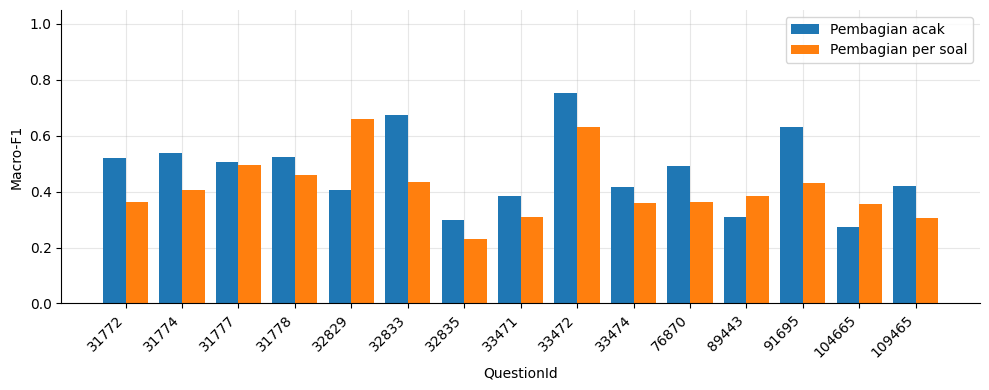

Rata-rata macro-F1 | acak: 0.4767 | per soal: 0.4129


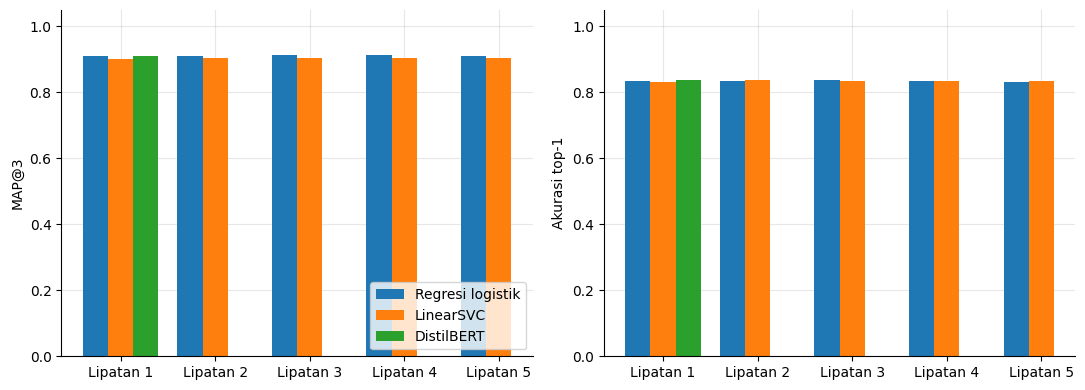

Gambar 3 dilewati: isi LOG_TEXT dengan log pelatihan DistilBERT.


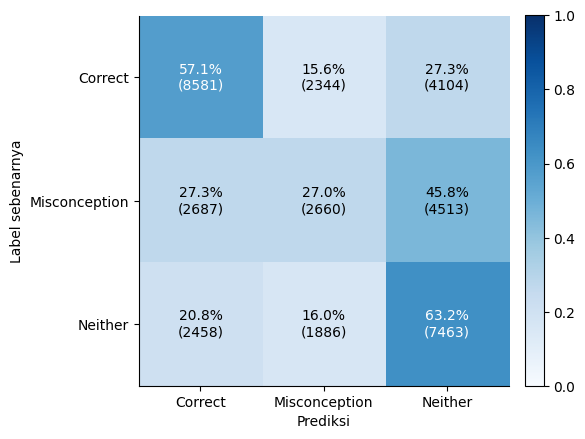

In [10]:
# ===== GAMBAR UNTUK MAKALAH =====
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import hstack
from sklearn.model_selection import StratifiedGroupKFold, GroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix

SIMPAN_GAMBAR = False       # True untuk menyimpan PNG ke folder output
DPI = 300

# Gambar 3: tempel log pelatihan DistilBERT di sini (baris "epoch x/3 | step n/T | loss L")
LOG_TEXT = """

"""

plt.rcParams.update({
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
})
CLASSES3 = ["Correct", "Misconception", "Neither"]


def selesai(fig, nama):
    fig.tight_layout()
    if SIMPAN_GAMBAR:
        fig.savefig(ROOT / f"{nama}.png", dpi=DPI, bbox_inches="tight")
    plt.show()


# ---------- Baseline ringan (tanpa fitur QuestionId agar adil di kedua pembagian) ----------
def target3(df):
    cat = df["Category"].astype(str)
    return np.where(cat.str.endswith("_Correct"), "Correct",
           np.where(cat.str.endswith("_Misconception"), "Misconception", "Neither"))


def oof_predict(df, y, splits):
    txt = text_context(df)
    expl = df["StudentExplanation"].astype(str).to_numpy()
    pred = np.empty(len(df), dtype=object)
    for tr_idx, va_idx in splits:
        word = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=.995, sublinear_tf=True,
                               max_features=20000, dtype=np.float32)
        char = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2,
                               sublinear_tf=True, max_features=5000, dtype=np.float32)
        Xtr = hstack([word.fit_transform(txt[tr_idx]), char.fit_transform(expl[tr_idx]) * 0.5], format="csr")
        Xva = hstack([word.transform(txt[va_idx]), char.transform(expl[va_idx]) * 0.5], format="csr")
        clf = LogisticRegression(C=1.0, solver="lbfgs", max_iter=200, tol=1e-2, random_state=42)
        clf.fit(Xtr, y[tr_idx])
        pred[va_idx] = clf.predict(Xva)
    return pred.astype(str)


fig_df = train_data.reset_index(drop=True)
y3 = target3(fig_df)
qids = fig_df["QuestionId"].astype(str).to_numpy()
expl_groups = fig_df["StudentExplanation"].map(norm_text).to_numpy()

t0 = time.time()
print("Menjalankan pembagian acak (grup penjelasan) ...")
split_acak = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
                  .split(fig_df, fig_df["Category"].astype(str), expl_groups))
pred_acak = oof_predict(fig_df, y3, split_acak)

print("Menjalankan pembagian per soal (GroupKFold berdasarkan QuestionId) ...")
split_soal = list(GroupKFold(n_splits=5).split(fig_df, y3, qids))
pred_soal = oof_predict(fig_df, y3, split_soal)
print(f"Selesai dalam {time.time() - t0:.1f} detik")

# ---------- Gambar 1: macro-F1 per soal ----------
soal_list = sorted(set(qids), key=lambda s: int(s) if s.isdigit() else s)
f1_acak, f1_soal = [], []
for q in soal_list:
    m = qids == q
    f1_acak.append(f1_score(y3[m], pred_acak[m], average="macro", zero_division=0))
    f1_soal.append(f1_score(y3[m], pred_soal[m], average="macro", zero_division=0))

x = np.arange(len(soal_list))
w = 0.4
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - w/2, f1_acak, w, label="Pembagian acak")
ax.bar(x + w/2, f1_soal, w, label="Pembagian per soal")
ax.set_xticks(x)
ax.set_xticklabels(soal_list, rotation=45, ha="right")
ax.set_xlabel("QuestionId")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1.05)
ax.legend()
selesai(fig, "gambar1_macroF1_per_soal")
print(f"Rata-rata macro-F1 | acak: {np.mean(f1_acak):.4f} | per soal: {np.mean(f1_soal):.4f}")

# ---------- Gambar 2: MAP@3 dan top-1 per lipatan ----------
metrik = {}
if "cv_results" in globals():
    metrik["Regresi logistik"] = (cv_results["MAP@3"].to_numpy(), cv_results["Top1 Accuracy"].to_numpy())
else:
    print("cv_results (regresi logistik) tidak ditemukan, jalankan cell 4.")

if "scores" in globals() and len(scores) > 0 and isinstance(scores[0], tuple):
    metrik["LinearSVC"] = (np.array([s[0] for s in scores]), np.array([s[1] for s in scores]))
else:
    print("scores (LinearSVC) tidak ditemukan, jalankan cell 6.")

if "fold_results" in globals() and len(fold_results) > 0:
    fr = pd.DataFrame(fold_results)
    metrik["DistilBERT"] = (fr["MAP@3"].to_numpy(), fr["Top1_Accuracy"].to_numpy())
else:
    print("fold_results (DistilBERT) tidak ditemukan, jalankan cell DistilBERT.")

if metrik:
    n_fold = max(len(v[0]) for v in metrik.values())
    nm = len(metrik)
    w = 0.8 / nm
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, idx, nama_metrik in zip(axes, (0, 1), ("MAP@3", "Akurasi top-1")):
        for k, (nama, vals) in enumerate(metrik.items()):
            v = np.full(n_fold, np.nan)
            v[:len(vals[idx])] = vals[idx]
            ax.bar(np.arange(n_fold) + (k - (nm - 1) / 2) * w, v, w, label=nama)
        ax.set_xticks(np.arange(n_fold))
        ax.set_xticklabels([f"Lipatan {i+1}" for i in range(n_fold)])
        ax.set_ylabel(nama_metrik)
        ax.set_ylim(0, 1.05)
    axes[0].legend(loc="lower right")
    selesai(fig, "gambar2_metrik_per_lipatan")

# ---------- Gambar 3: kurva loss DistilBERT ----------
pola = re.compile(r"epoch\s+(\d+)/(\d+)\s*\|\s*step\s+(\d+)/(\d+)\s*\|\s*loss\s+([0-9.]+)")
baris = pola.findall(LOG_TEXT)
if baris:
    steps = np.array([int(b[2]) for b in baris])
    loss = np.array([float(b[4]) for b in baris])
    total_epoch = int(baris[0][1])
    total_steps = int(baris[0][3])
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(steps, loss, marker="o", markersize=3, linewidth=1.5)
    for e in range(1, total_epoch):
        ax.axvline(total_steps * e / total_epoch, color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel("Langkah pelatihan")
    ax.set_ylabel("Loss pelatihan")
    selesai(fig, "gambar3_kurva_loss")
else:
    print("Gambar 3 dilewati: isi LOG_TEXT dengan log pelatihan DistilBERT.")

# ---------- Gambar 4: matriks konfusi baseline (pembagian per soal) ----------
cm = confusion_matrix(y3, pred_soal, labels=CLASSES3)
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.grid(False)
ax.set_xticks(range(3)); ax.set_xticklabels(CLASSES3)
ax.set_yticks(range(3)); ax.set_yticklabels(CLASSES3)
ax.set_xlabel("Prediksi")
ax.set_ylabel("Label sebenarnya")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm_norm[i, j]*100:.1f}%\n({cm[i, j]})", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
selesai(fig, "gambar4_matriks_konfusi")

In [11]:
# ===== CELL 10 (REVISI): DETEKSI MISKONSEPSI UNTUK SOAL BARU =====
# Ide utama
#   1. Model dilatih pada data Inggris asli, tanpa terjemahan data latih.
#   2. Input soal baru berbahasa Indonesia diterjemahkan ID -> EN hanya saat prediksi,
#      dengan pemilihan kandidat terjemahan yang menjaga angka tetap sama.
#   3. Label hasil dipetakan ke bahasa Indonesia lewat kamus, bukan lewat mesin terjemah.
#   4. Fokus pada DETEKSI 3 kelas (Correct, Misconception, Neither), karena hanya deteksi
#      yang dapat digeneralisasi ke soal baru. Nama miskonsepsi bersifat indikatif.
#   5. Evaluasi memakai leave-one-question-out (protokol P-B makalah) untuk membandingkan
#      varian V0 sampai V3, lengkap dengan uji Wilcoxon dan selang kepercayaan bootstrap.

import re
import json
import time
import gc
import pickle
import warnings
from fractions import Fraction
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.stats import wilcoxon
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

try:
    display
except NameError:
    display = print

# ============================ A. KONFIGURASI ============================
SEED = 42
PROTOKOL = "loqo"            # "loqo" = 15 lipatan (sesuai makalah), "group5" = 5 lipatan (lebih cepat)
VARIAN_UJI = ["V0", "V1", "V2", "V3"]
VARIAN_FINAL = None          # None = pilih otomatis dari macro-F1 rata-rata antar soal
PAKAI_EMBEDDING = True       # dibutuhkan V3, otomatis dilewati bila model tidak dapat diunduh
EMB_MODEL = "sentence-transformers/all-MiniLM-L6-v2"

C_MODEL = 1.0
BOBOT_CHAR = 0.5
BOBOT_META = 1.0
BOBOT_EMB = 1.0
TARGET_AKURASI_TERLAYANI = 0.80   # untuk memilih ambang keyakinan "tinjau guru"

MT_MODEL = "Helsinki-NLP/opus-mt-id-en"
MT_BEAMS = 8
MT_NBEST = 4

JALANKAN_EVALUASI = True
JALANKAN_TES_BARU = True
SIMPAN_HASIL = True

ROOT_OUT = Path(globals().get("ROOT", Path.cwd() / "output"))
ROOT_OUT.mkdir(parents=True, exist_ok=True)

KELAS3 = ["Correct", "Misconception", "Neither"]
LABEL3_ID = {"Correct": "Benar", "Misconception": "Miskonsepsi", "Neither": "Tidak jelas"}
DESKRIPSI = {
    "V0": "Baseline makalah (TF-IDF kata, hanya penjelasan)",
    "V1": "Teks + angka dimasking + karakter + fitur umum",
    "V2": "V1 + status kunci jawaban (interaksi benar/salah)",
    "V3": "V2 + embedding kalimat",
}

# Glosarium nama miskonsepsi. Hanya nama yang maknanya jelas dari namanya diterjemahkan.
# Nama lain dipakai apa adanya (Inggris). Terjemahan ini draf dan perlu divalidasi guru.
NAMA_MISKONSEPSI_ID = {
    "Adding_across": "Menjumlahkan pembilang dengan pembilang dan penyebut dengan penyebut",
    "Adding_terms": "Menjumlahkan suku-suku",
    "Additive": "Berpikir aditif",
    "Base_rate": "Mengabaikan laju dasar (base rate)",
    "Certainty": "Menganggap kejadian pasti",
    "Incomplete": "Penjelasan tidak lengkap",
    "Irrelevant": "Penjelasan tidak relevan",
    "Longer_is_bigger": "Desimal yang lebih panjang dianggap lebih besar",
    "Shorter_is_larger": "Desimal yang lebih pendek dianggap lebih besar",
    "Not_variable": "Huruf tidak diperlakukan sebagai variabel",
    "Unknowable": "Menganggap tidak dapat diketahui",
    "Whole_numbers_larger": "Bilangan bulat dianggap lebih besar",
    "Wrong_Fraction": "Pecahan yang dipakai salah",
    "Wrong_Operation": "Operasi yang dipakai salah",
}

# Soal baru (bahasa Indonesia). "jawaban_benar" adalah kunci dari guru.
# Jawaban boleh berbentuk "3/8", "0,5", atau teks pendek.
SOAL_BARU = {
    "soal": "Mia memiliki 3/4 pizza dan makan setengah dari yang dia miliki. "
            "Berapa bagian dari seluruh pizza yang dia makan?",
    "jawaban_benar": "3/8",
    "item": [
        {"penjelasan": "Saya mengalikan 3/4 dengan 1/2 dan mendapat 3/8.", "jawaban": "3/8"},
        {"penjelasan": "Saya menjumlahkan 3/4 dan 1/2 jadi 4/6.", "jawaban": "4/6"},
        {"penjelasan": "Saya tidak tahu.", "jawaban": "3/8"},
        {"penjelasan": "Setengah dari tiga perempat itu tiga per delapan.", "jawaban": "3/8"},
        {"penjelasan": "Karena 3 + 1 = 4 dan 4 + 2 = 6.", "jawaban": "4/6"},
    ],
}

# ============================ B. UTILITAS TEKS DAN FITUR ============================
def rapikan(x):
    if pd.isna(x):
        return ""
    s = str(x).replace("\u200b", " ").replace("\ufeff", " ")
    return re.sub(r"\s+", " ", s).strip().lower()


def mask_angka(t):
    """Pecahan dan angka diganti token generik agar pola penalaran terbawa lintas soal."""
    t = re.sub(r"\d+\s*/\s*\d+", " tokfrac ", t)
    t = re.sub(r"\d+(?:[.,]\d+)?", " toknum ", t)
    return re.sub(r"\s+", " ", t).strip()


def angka_dari(t):
    return [a.replace(",", ".") for a in re.findall(r"\d+(?:[.,]\d+)?", str(t))]


def target3(df):
    cat = df["Category"].astype(str)
    return np.where(cat.str.endswith("_Correct"), "Correct",
                    np.where(cat.str.endswith("_Misconception"), "Misconception", "Neither"))


def nama_miskonsepsi(df):
    """Nama miskonsepsi dengan huruf besar-kecil diseragamkan (35 nama menjadi 34)."""
    nm = df["Misconception"].fillna("").astype(str).str.strip()
    nm = nm.where(~nm.str.lower().isin(["", "nan", "none", "na"]), "")
    kanon = nm[nm != ""].groupby(nm[nm != ""].str.lower()).agg(lambda s: s.value_counts().idxmax())
    return nm.str.lower().map(kanon).fillna("").to_numpy(dtype=str)


def fitur_meta(expl, soal, jawab):
    """Fitur numerik yang tidak bergantung pada identitas soal."""
    baris = []
    for e, q, a in zip(expl, soal, jawab):
        e = rapikan(e)
        ne = angka_dari(e)
        se, sq, sa = set(ne), set(angka_dari(q)), set(angka_dari(a))
        baris.append([
            np.log1p(len(e.split())),
            np.log1p(len(e)),
            float(len(ne) > 0),
            np.log1p(len(ne)),
            len(se & sq) / len(se) if se else 0.0,
            len(se & sa) / len(sa) if sa else 0.0,
            len(se & sa) / len(se) if se else 0.0,
            np.log1p(len(re.findall(r"[+\-*/=\u00d7\u00f7^]", e))),
            float("?" in e),
        ])
    return np.asarray(baris, dtype=np.float32)


def ke_pecahan(s):
    s = re.sub(r"\\\(|\\\)", "", str(s)).strip().replace(" ", "").replace(",", ".")
    m = re.fullmatch(r"\\frac\{(\d+)\}\{(\d+)\}", s)
    if m:
        s = f"{m.group(1)}/{m.group(2)}"
    try:
        return Fraction(s)
    except (ValueError, ZeroDivisionError):
        return None


def jawaban_sama(a, b):
    fa, fb = ke_pecahan(a), ke_pecahan(b)
    if fa is not None and fb is not None:
        return fa == fb
    return re.sub(r"\s+", "", str(a).lower()) == re.sub(r"\s+", "", str(b).lower())


def format_mc(a):
    """'3/8' menjadi '\\( \\frac{3}{8} \\)' agar sama dengan format MC_Answer pada data latih."""
    a = str(a).strip()
    m = re.fullmatch(r"(\d+)\s*/\s*(\d+)", a)
    if m:
        return rf"\( \frac{{{m.group(1)}}}{{{m.group(2)}}} \)"
    return rf"\( {a} \)"


def f1m(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=KELAS3, average="macro", zero_division=0)


# ============================ C. EKSTRAKTOR FITUR DAN MODEL ============================
class Ekstraktor:
    """Semua vectorizer dilatih hanya pada data latih tiap lipatan (tanpa kebocoran)."""

    def __init__(self):
        self.vr = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                                  max_features=30000, dtype=np.float32)
        self.vm = TfidfVectorizer(ngram_range=(1, 3), min_df=2, sublinear_tf=True,
                                  max_features=30000, dtype=np.float32)
        self.vc = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3,
                                  sublinear_tf=True, max_features=20000, dtype=np.float32)
        self.sc = StandardScaler()

    def fit_transform(self, raw, mask, meta):
        return {"r": self.vr.fit_transform(raw), "m": self.vm.fit_transform(mask),
                "c": self.vc.fit_transform(mask),
                "meta": sp.csr_matrix(self.sc.fit_transform(meta))}

    def transform(self, raw, mask, meta):
        return {"r": self.vr.transform(raw), "m": self.vm.transform(mask),
                "c": self.vc.transform(mask),
                "meta": sp.csr_matrix(self.sc.transform(meta))}


def iris_blok(blok, idx):
    return {k: v[idx] for k, v in blok.items()}


def rakit(blok, flag, emb, varian):
    """Menyusun matriks fitur untuk satu varian."""
    if varian == "V0":
        return blok["r"].tocsr()
    teks = sp.hstack([blok["r"], blok["m"], BOBOT_CHAR * blok["c"]], format="csr")
    meta = BOBOT_META * blok["meta"]
    if varian == "V1":
        return sp.hstack([teks, meta], format="csr")
    f, g = sp.diags(flag), sp.diags(1.0 - flag)
    bagian = [(f @ teks), (g @ teks), sp.csr_matrix(flag[:, None]), meta]
    if varian == "V3":
        if emb is None:
            raise ValueError("V3 membutuhkan embedding")
        e = BOBOT_EMB * emb
        bagian += [sp.csr_matrix(e * flag[:, None]), sp.csr_matrix(e * (1.0 - flag)[:, None])]
    return sp.hstack(bagian, format="csr")


def buat_lr(varian):
    if varian == "V0":
        return LogisticRegression(C=2.0, class_weight="balanced", max_iter=2000)
    return LogisticRegression(C=C_MODEL, class_weight="balanced", max_iter=300, tol=1e-3)


def proba_kelas3(model, X):
    P = model.predict_proba(X)
    out = np.zeros((P.shape[0], 3), dtype=np.float64)
    for j, c in enumerate(model.classes_):
        out[:, KELAS3.index(c)] = P[:, j]
    return out


def terapkan_kendala(P, flag, aktif):
    """Correct mustahil bila jawaban salah (diperiksa dari data latih, lihat bagian D)."""
    if not aktif:
        return P
    P = P.copy()
    P[flag < 0.5, KELAS3.index("Correct")] = 0.0
    s = P.sum(axis=1, keepdims=True)
    s[s == 0] = 1.0
    return P / s


# ============================ D. DATA ============================
sumber = globals().get("train_data", globals().get("train_raw"))
if sumber is None:
    raise RuntimeError("train_data atau train_raw belum ada. Jalankan cell pemuatan data lebih dulu.")

df = sumber.reset_index(drop=True).copy()
N = len(df)
raw_expl = np.array([rapikan(t) for t in df["StudentExplanation"]], dtype=object)
mask_expl = np.array([mask_angka(t) for t in raw_expl], dtype=object)
meta_all = fitur_meta(raw_expl, df["QuestionText"].fillna(""), df["MC_Answer"].fillna(""))
y3 = target3(df)
flag = df["Category"].astype(str).str.startswith("True_").to_numpy(dtype=np.float64)
qid = df["QuestionId"].to_numpy()
nama_all = nama_miskonsepsi(df)

n_benar_salah = int(((flag == 0) & (y3 == "Correct")).sum())
KENDALA_CORRECT = n_benar_salah == 0
n_kunci = df.assign(t=flag).groupby("QuestionId")["t"].apply(
    lambda s: df.loc[s.index[s > 0], "MC_Answer"].nunique())
print("=" * 70)
print("RINGKASAN DATA")
print("=" * 70)
print(f"Baris: {N} | soal: {len(np.unique(qid))} | distribusi 3 kelas: "
      f"{dict(pd.Series(y3).value_counts())}")
print(f"Baris berlabel Correct padahal jawaban salah: {n_benar_salah} "
      f"-> kendala 'Correct hanya untuk jawaban benar' {'AKTIF' if KENDALA_CORRECT else 'TIDAK dipakai'}")
print(f"Jumlah pilihan jawaban benar per soal (min/maks): {n_kunci.min()}/{n_kunci.max()}")
print("Status kunci jawaban (V2 dan V3) diasumsikan diberikan guru saat membuat soal.")

# ============================ E. EMBEDDING DAN TERJEMAHAN ============================
class PenyematKalimat:
    def __init__(self, nama, cache_path):
        self.nama, self.cache_path = nama, Path(cache_path)
        self.cache, self._tok, self._mdl = {}, None, None
        if self.cache_path.exists():
            with open(self.cache_path, "rb") as f:
                self.cache = pickle.load(f)

    def _muat(self):
        import torch
        from transformers import AutoTokenizer, AutoModel
        self._torch = torch
        self._dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self._tok = AutoTokenizer.from_pretrained(self.nama)
        self._mdl = AutoModel.from_pretrained(self.nama).to(self._dev).eval()

    def encode(self, teks, batch=64, max_len=64):
        teks = [str(t) for t in teks]
        todo = sorted((t for t in dict.fromkeys(teks) if t not in self.cache), key=len)
        if todo:
            if self._mdl is None:
                self._muat()
            torch = self._torch
            t0 = time.time()
            for i in range(0, len(todo), batch):
                b = todo[i:i + batch]
                enc = self._tok(b, padding=True, truncation=True, max_length=max_len,
                                return_tensors="pt").to(self._dev)
                with torch.no_grad():
                    h = self._mdl(**enc).last_hidden_state
                m = enc["attention_mask"].unsqueeze(-1).to(h.dtype)
                e = (h * m).sum(1) / m.sum(1).clamp(min=1)
                e = torch.nn.functional.normalize(e, dim=1).cpu().numpy().astype(np.float32)
                for t, v in zip(b, e):
                    self.cache[t] = v
                if (i // batch) % 50 == 0:
                    print(f"  embedding {min(i + batch, len(todo))}/{len(todo)} | {time.time() - t0:.0f} dtk")
            with open(self.cache_path, "wb") as f:
                pickle.dump(self.cache, f)
        return np.vstack([self.cache[t] for t in teks]).astype(np.float32)


def pilih_kandidat(src, kandidat):
    """Pilih kandidat terjemahan pertama yang angkanya sama dengan sumber."""
    target = sorted(angka_dari(src))
    if not target:
        return kandidat[0]
    for k in kandidat:
        if sorted(angka_dari(k)) == target:
            return k
    return kandidat[0]


class PenerjemahIDEN:
    def __init__(self, nama, cache_path, beams, nbest):
        self.nama, self.cache_path = nama, Path(cache_path)
        self.beams, self.nbest = beams, nbest
        self.cache, self._tok, self._mdl = {}, None, None
        if self.cache_path.exists():
            self.cache = json.loads(self.cache_path.read_text(encoding="utf-8"))

    def _muat(self):
        import torch
        from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
        self._torch = torch
        self._dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self._tok = AutoTokenizer.from_pretrained(self.nama)
        self._mdl = AutoModelForSeq2SeqLM.from_pretrained(self.nama).to(self._dev).eval()

    def terjemah(self, teks, batch=8):
        teks = [str(t) for t in teks]
        todo = [t for t in dict.fromkeys(teks) if t.strip() and t not in self.cache]
        if todo:
            if self._mdl is None:
                self._muat()
            torch = self._torch
            for i in range(0, len(todo), batch):
                b = todo[i:i + batch]
                enc = self._tok(b, return_tensors="pt", padding=True, truncation=True,
                                max_length=128).to(self._dev)
                with torch.no_grad():
                    out = self._mdl.generate(**enc, num_beams=max(self.beams, self.nbest),
                                             num_return_sequences=self.nbest, max_new_tokens=128)
                dec = self._tok.batch_decode(out, skip_special_tokens=True)
                for j, src in enumerate(b):
                    self.cache[src] = pilih_kandidat(src, dec[j * self.nbest:(j + 1) * self.nbest])
            self.cache_path.write_text(json.dumps(self.cache, ensure_ascii=False), encoding="utf-8")
        return [self.cache.get(t, t) for t in teks]


_PENERJEMAH = None
_PENYEMAT = None


def terjemahkan_id_en(teks):
    global _PENERJEMAH
    if _PENERJEMAH is None:
        _PENERJEMAH = PenerjemahIDEN(MT_MODEL, ROOT_OUT / "translation_cache_id_en_v2.json",
                                     MT_BEAMS, MT_NBEST)
    return _PENERJEMAH.terjemah(teks)


def embed(teks):
    global _PENYEMAT
    if _PENYEMAT is None:
        _PENYEMAT = PenyematKalimat(EMB_MODEL, ROOT_OUT / "emb_cache_minilm.pkl")
    return _PENYEMAT.encode(teks)


EMB_ALL = None
if "V3" in VARIAN_UJI or VARIAN_FINAL == "V3":
    if PAKAI_EMBEDDING:
        try:
            print("\nMenghitung embedding kalimat untuk seluruh penjelasan (hasil disimpan di cache)...")
            EMB_ALL = embed(list(raw_expl))
        except Exception as e:
            print(f"Embedding dilewati ({type(e).__name__}: {e}). Varian V3 dinonaktifkan.")
    if EMB_ALL is None:
        VARIAN_UJI = [v for v in VARIAN_UJI if v != "V3"]
        if VARIAN_FINAL == "V3":
            VARIAN_FINAL = None

# ============================ F. EVALUASI PADA SOAL BARU (LEAVE-ONE-QUESTION-OUT) ============================
def daftar_lipatan(qid_arr):
    uniq = np.unique(qid_arr)
    if PROTOKOL == "loqo":
        return [[u] for u in uniq]
    perm = np.random.RandomState(SEED).permutation(uniq)
    return [list(perm[k::5]) for k in range(5)]


hasil_eval = None
OOF = {}
if JALANKAN_EVALUASI:
    print("\n" + "=" * 70)
    print(f"EVALUASI PER SOAL (protokol {PROTOKOL}), varian: {VARIAN_UJI}")
    print("=" * 70)
    lipatan = daftar_lipatan(qid)
    OOF = {v: np.zeros((N, 3)) for v in VARIAN_UJI}
    skor_soal = {v: {} for v in VARIAN_UJI}
    t_mulai = time.time()

    for k, grup in enumerate(lipatan, 1):
        te = np.isin(qid, grup)
        tr = ~te
        ek = Ekstraktor()
        b_tr = ek.fit_transform(raw_expl[tr], mask_expl[tr], meta_all[tr])
        b_te = ek.transform(raw_expl[te], mask_expl[te], meta_all[te])
        baris_log = []
        for v in VARIAN_UJI:
            e_tr = EMB_ALL[tr] if v == "V3" else None
            e_te = EMB_ALL[te] if v == "V3" else None
            m = buat_lr(v).fit(rakit(b_tr, flag[tr], e_tr, v), y3[tr])
            P = proba_kelas3(m, rakit(b_te, flag[te], e_te, v))
            if v in ("V2", "V3"):
                P = terapkan_kendala(P, flag[te], KENDALA_CORRECT)
            OOF[v][te] = P
            pred = np.array(KELAS3)[P.argmax(1)]
            skor = f1m(y3[te], pred)
            for s in np.unique(qid[te]):
                ms = qid[te] == s
                skor_soal[v][s] = f1m(y3[te][ms], pred[ms])
            baris_log.append(f"{v}={skor:.3f}")
        print(f"lipatan {k}/{len(lipatan)} | soal uji {[int(g) for g in grup]} | macro-F1: {' '.join(baris_log)} "
              f"| {time.time() - t_mulai:.0f} dtk")
        del b_tr, b_te
        gc.collect()

    # ---------- ringkasan ----------
    ringkas = []
    for v in VARIAN_UJI:
        pred = np.array(KELAS3)[OOF[v].argmax(1)]
        per_soal = np.array([skor_soal[v][s] for s in sorted(skor_soal[v])])
        rec = recall_score(y3, pred, labels=KELAS3, average=None, zero_division=0)
        ringkas.append({
            "varian": v, "deskripsi": DESKRIPSI[v],
            "macroF1_gabungan": f1m(y3, pred),
            "macroF1_rata2_soal": per_soal.mean(), "sd_antar_soal": per_soal.std(ddof=1),
            "akurasi": accuracy_score(y3, pred),
            "recall_Correct": rec[0], "recall_Misconception": rec[1], "recall_Neither": rec[2],
        })
    hasil_eval = pd.DataFrame(ringkas).round(4)
    print("\nRINGKASAN DETEKSI PADA SOAL BARU")
    display(hasil_eval)

    # ---------- tabel per soal ----------
    ket = df.drop_duplicates("QuestionId").set_index("QuestionId")["QuestionText"].str.slice(0, 45)
    tabel_soal = pd.DataFrame({v: pd.Series(skor_soal[v]) for v in VARIAN_UJI}).round(3)
    tabel_soal.insert(0, "soal", [ket.get(s, "") for s in tabel_soal.index])
    print("\nMACRO-F1 PER SOAL")
    display(tabel_soal)

    # ---------- uji statistik terhadap baseline ----------
    terbaik = hasil_eval.sort_values("macroF1_rata2_soal", ascending=False)["varian"].iloc[0]
    if "V0" in VARIAN_UJI:
        print("\nPERBANDINGAN DENGAN BASELINE V0 (unit analisis = soal)")
        rng = np.random.RandomState(SEED)
        for v in VARIAN_UJI:
            if v == "V0":
                continue
            a = np.array([skor_soal[v][s] for s in sorted(skor_soal[v])])
            b = np.array([skor_soal["V0"][s] for s in sorted(skor_soal["V0"])])
            d = a - b
            try:
                p = wilcoxon(d).pvalue
            except ValueError:
                p = float("nan")
            boot = [d[rng.randint(0, len(d), len(d))].mean() for _ in range(5000)]
            lo, hi = np.percentile(boot, [2.5, 97.5])
            print(f"  {v} vs V0: selisih rata-rata {d.mean():+.3f} | CI95% bootstrap [{lo:+.3f}, {hi:+.3f}] "
                  f"| Wilcoxon p={p:.2g} | lebih baik pada {int((d > 0).sum())}/{len(d)} soal")

    # ---------- prediksi selektif (penyaring awal untuk guru) ----------
    P = OOF[terbaik]
    pred = np.array(KELAS3)[P.argmax(1)]
    conf = P.max(1)
    grid = np.round(np.arange(0.35, 0.96, 0.05), 2)
    baris_sel = []
    for t in grid:
        ms = conf >= t
        if ms.sum() < 50:
            continue
        baris_sel.append({"ambang": t, "cakupan": ms.mean(),
                          "akurasi_terlayani": (pred[ms] == y3[ms]).mean(),
                          "macroF1_terlayani": f1m(y3[ms], pred[ms])})
    tabel_sel = pd.DataFrame(baris_sel).round(3)
    print(f"\nPREDIKSI SELEKTIF ({terbaik}): baris di bawah ambang diserahkan ke guru")
    display(tabel_sel)
    layak = tabel_sel[(tabel_sel["akurasi_terlayani"] >= TARGET_AKURASI_TERLAYANI) & (tabel_sel["cakupan"] >= 0.2)]
    AMBANG = float(layak["ambang"].iloc[0]) if len(layak) else 0.5

    if SIMPAN_HASIL:
        hasil_eval.to_csv(ROOT_OUT / "DIAMIS_v2_ringkasan_loqo.csv", index=False)
        tabel_soal.to_csv(ROOT_OUT / "DIAMIS_v2_per_soal.csv")
        tabel_sel.to_csv(ROOT_OUT / "DIAMIS_v2_prediksi_selektif.csv", index=False)
else:
    terbaik, AMBANG = "V2", 0.5

VARIAN_PAKAI = VARIAN_FINAL or terbaik
if VARIAN_PAKAI == "V3" and EMB_ALL is None:
    VARIAN_PAKAI = "V2"
print(f"\nVarian untuk model akhir: {VARIAN_PAKAI} | ambang keyakinan: {AMBANG:.2f}")

# ============================ G. MODEL AKHIR (SELURUH DATA INGGRIS ASLI) ============================
ek_final = Ekstraktor()
b_all = ek_final.fit_transform(raw_expl, mask_expl, meta_all)
model_det = buat_lr(VARIAN_PAKAI).fit(
    rakit(b_all, flag, EMB_ALL if VARIAN_PAKAI == "V3" else None, VARIAN_PAKAI), y3)

# Model nama miskonsepsi: hanya baris bermiskonsepsi, fitur varian V2 (tanpa identitas soal).
idx_m = (y3 == "Misconception") & (nama_all != "")
model_nama = LogisticRegression(C=C_MODEL, max_iter=300, tol=1e-3).fit(
    rakit(iris_blok(b_all, idx_m), flag[idx_m], None, "V2"), nama_all[idx_m])
print(f"Model akhir dilatih pada {N} baris | nama miskonsepsi: {len(model_nama.classes_)} kelas")


def prediksi_item(soal_en, penjelasan_en, jawaban, kunci):
    n = len(penjelasan_en)
    raw = np.array([rapikan(t) for t in penjelasan_en], dtype=object)
    msk = np.array([mask_angka(t) for t in raw], dtype=object)
    mc = [format_mc(a) for a in jawaban]
    meta = fitur_meta(raw, [soal_en] * n, mc)
    f = np.array([float(jawaban_sama(a, kunci)) for a in jawaban])
    blok = ek_final.transform(raw, msk, meta)
    emb = embed(list(raw)) if VARIAN_PAKAI == "V3" else None
    P = proba_kelas3(model_det, rakit(blok, f, emb, VARIAN_PAKAI))
    P = terapkan_kendala(P, f, KENDALA_CORRECT)
    Pn = model_nama.predict_proba(rakit(blok, f, None, "V2"))
    return P, Pn, f


def nama_id(n):
    return NAMA_MISKONSEPSI_ID.get(n, n)


# ============================ H. TES SOAL BARU (INPUT BAHASA INDONESIA) ============================
if JALANKAN_TES_BARU:
    print("\n" + "=" * 70)
    print("TES SOAL BARU: input Indonesia diterjemahkan ke Inggris, model dilatih pada data Inggris asli")
    print("=" * 70)
    item = SOAL_BARU["item"]
    soal_en = terjemahkan_id_en([SOAL_BARU["soal"]])[0]
    penj_en = terjemahkan_id_en([it["penjelasan"] for it in item])
    jawaban = [it["jawaban"] for it in item]

    for it, en in zip(item, penj_en):
        if angka_dari(it["penjelasan"]) and sorted(angka_dari(it["penjelasan"])) != sorted(angka_dari(en)):
            print(f"PERINGATAN angka berubah saat terjemahan: '{it['penjelasan']}' -> '{en}'")
    if sorted(angka_dari(SOAL_BARU["soal"])) != sorted(angka_dari(soal_en)):
        print("PERINGATAN: angka pada teks soal berubah saat terjemahan.")
    print("Soal (EN):", soal_en, "\n")

    P, Pn, f = prediksi_item(soal_en, penj_en, jawaban, SOAL_BARU["jawaban_benar"])
    baris = []
    for i, it in enumerate(item):
        urut = np.argsort(-P[i])
        top = KELAS3[urut[0]]
        yakin = P[i, urut[0]]
        tinjau = yakin < AMBANG
        nama_top3 = "-"
        if top == "Misconception":
            j3 = np.argsort(-Pn[i])[:3]
            nama_top3 = "; ".join(f"{nama_id(model_nama.classes_[j])} {Pn[i, j]:.2f}" for j in j3)
        baris.append({
            "Penjelasan (ID)": it["penjelasan"],
            "Terjemahan (EN)": penj_en[i],
            "Jawaban": it["jawaban"],
            "Kunci": "benar" if f[i] > 0.5 else "salah",
            "Probabilitas": " | ".join(f"{LABEL3_ID[KELAS3[j]]} {P[i, j]:.2f}" for j in urut),
            "Keputusan": ("TINJAU GURU (" if tinjau else "") + LABEL3_ID[top] + (")" if tinjau else ""),
            "Nama miskonsepsi (indikatif)": nama_top3,
        })
    pd.set_option("display.max_colwidth", 70)
    pd.set_option("display.width", 250)
    display(pd.DataFrame(baris))
    print("Catatan: soal ini tidak ada di data latih. Kualitas model dibaca dari bagian F, bukan dari tabel ini.")
    print("Nama miskonsepsi pada soal baru hanya indikatif: sekitar 70% nama khas satu soal (batas atas ~0,30).")

RINGKASAN DATA
Baris: 36696 | soal: 15 | distribusi 3 kelas: {'Correct': np.int64(15029), 'Neither': np.int64(11807), 'Misconception': np.int64(9860)}
Baris berlabel Correct padahal jawaban salah: 227 -> kendala 'Correct hanya untuk jawaban benar' TIDAK dipakai
Jumlah pilihan jawaban benar per soal (min/maks): 1/2
Status kunci jawaban (V2 dan V3) diasumsikan diberikan guru saat membuat soal.

Menghitung embedding kalimat untuk seluruh penjelasan (hasil disimpan di cache)...

EVALUASI PER SOAL (protokol loqo), varian: ['V0', 'V1', 'V2', 'V3']
lipatan 1/15 | soal uji [31772] | macro-F1: V0=0.336 V1=0.361 V2=0.571 V3=0.623 | 91 dtk
lipatan 2/15 | soal uji [31774] | macro-F1: V0=0.437 V1=0.452 V2=0.630 V3=0.614 | 186 dtk
lipatan 3/15 | soal uji [31777] | macro-F1: V0=0.365 V1=0.441 V2=0.712 V3=0.679 | 294 dtk
lipatan 4/15 | soal uji [31778] | macro-F1: V0=0.540 V1=0.604 V2=0.729 V3=0.748 | 396 dtk
lipatan 5/15 | soal uji [32829] | macro-F1: V0=0.585 V1=0.503 V2=0.726 V3=0.747 | 518 dtk
lip

,varian,deskripsi,macroF1_gabungan,macroF1_rata2_soal,sd_antar_soal,akurasi,recall_Correct,recall_Misconception,recall_Neither
0,V0,"Baseline makalah (TF-IDF kata, hanya penjelasan)",0.4247,0.3832,0.0921,0.4439,0.3413,0.2887,0.7040
1,V1,Teks + angka dimasking + karakter + fitur umum,0.4702,0.4243,0.1047,0.4832,0.3871,0.3644,0.7047
2,V2,V1 + status kunci jawaban (interaksi benar/salah),0.6616,0.6298,0.1402,0.6663,0.7271,0.5722,0.6673
3,V3,V2 + embedding kalimat,0.6591,0.6096,0.1515,0.6561,0.6529,0.6116,0.6973



MACRO-F1 PER SOAL


,soal,V0,V1,V2,V3
31772,What fraction of the shape is not shaded? Giv,0.336,0.361,0.571,0.623
31774,Calculate \( \frac{1}{2} \div 6 \),0.437,0.452,0.630,0.614
31777,A box contains \( 120 \) counters. The counte,0.365,0.441,0.712,0.679
31778,\( \frac{A}{10}=\frac{9}{15} \) What is the v,0.540,0.604,0.729,0.748
32829,\( 2 y=24 \) What is the value of \( y \) ?,0.585,0.503,0.726,0.747
32833,Calculate \( \frac{2}{3} \times 5 \),0.426,0.517,0.730,0.733
32835,Which number is the greatest?,0.236,0.271,0.333,0.330
33471,A bag contains \( 24 \) yellow and green ball,0.352,0.423,0.782,0.757
33472,\( \frac{1}{3}+\frac{2}{5}= \),0.420,0.586,0.756,0.711
33474,Sally has \( \frac{2}{3} \) of a whole cake i,0.415,0.455,0.667,0.648



PERBANDINGAN DENGAN BASELINE V0 (unit analisis = soal)
  V1 vs V0: selisih rata-rata +0.041 | CI95% bootstrap [+0.013, +0.070] | Wilcoxon p=0.022 | lebih baik pada 12/15 soal
  V2 vs V0: selisih rata-rata +0.247 | CI95% bootstrap [+0.191, +0.303] | Wilcoxon p=6.1e-05 | lebih baik pada 15/15 soal
  V3 vs V0: selisih rata-rata +0.226 | CI95% bootstrap [+0.170, +0.282] | Wilcoxon p=0.00012 | lebih baik pada 14/15 soal

PREDIKSI SELEKTIF (V2): baris di bawah ambang diserahkan ke guru


,ambang,cakupan,akurasi_terlayani,macroF1_terlayani
0,0.35,1.000,0.666,0.662
1,0.40,0.999,0.667,0.662
2,0.45,0.997,0.667,0.662
3,0.50,0.976,0.671,0.666
4,0.55,0.894,0.687,0.680
5,0.60,0.813,0.701,0.694
6,0.65,0.731,0.716,0.708
7,0.70,0.642,0.732,0.723
8,0.75,0.554,0.751,0.742
9,0.80,0.454,0.773,0.762



Varian untuk model akhir: V2 | ambang keyakinan: 0.90
Model akhir dilatih pada 36696 baris | nama miskonsepsi: 34 kelas

TES SOAL BARU: input Indonesia diterjemahkan ke Inggris, model dilatih pada data Inggris asli
Soal (EN): Mia had 3/4 pizzas and ate half of what she had. 



,Penjelasan (ID),Terjemahan (EN),Jawaban,Kunci,Probabilitas,Keputusan,Nama miskonsepsi (indikatif)
0,Saya mengalikan 3/4 dengan 1/2 dan mendapat 3/8.,I multiply 3/4 by 1/2 and get 3/8.,3/8,benar,Benar 0.56 | Tidak jelas 0.43 | Miskonsepsi 0.01,TINJAU GURU (Benar),-
1,Saya menjumlahkan 3/4 dan 1/2 jadi 4/6.,I add 3/4 and 1/2 to 4/6.,4/6,salah,Tidak jelas 0.72 | Miskonsepsi 0.25 | Benar 0.03,TINJAU GURU (Tidak jelas),-
2,Saya tidak tahu.,I don't know.,3/8,benar,Tidak jelas 0.99 | Benar 0.01 | Miskonsepsi 0.00,Tidak jelas,-
3,Setengah dari tiga perempat itu tiga per delapan.,Half of three quarters is three-eighths.,3/8,benar,Tidak jelas 0.88 | Benar 0.11 | Miskonsepsi 0.02,TINJAU GURU (Tidak jelas),-
4,Karena 3 + 1 = 4 dan 4 + 2 = 6.,Because 3 + 1 = 4 and 4 + 2 = 6.,4/6,salah,Miskonsepsi 0.97 | Tidak jelas 0.03 | Benar 0.01,Miskonsepsi,Menjumlahkan pembilang dengan pembilang dan penyebut dengan penyeb...


Catatan: soal ini tidak ada di data latih. Kualitas model dibaca dari bagian F, bukan dari tabel ini.
Nama miskonsepsi pada soal baru hanya indikatif: sekitar 70% nama khas satu soal (batas atas ~0,30).


In [14]:
# ===== CELL 11: PENINGKATAN AKURASI PADA SOAL BARU =====
# Syarat: cell 10 sudah selesai dijalankan dengan V2 dan V3 aktif (PAKAI_EMBEDDING = True).
# Perbaikan:
#   1. Ensemble V2 + V3 (rata-rata probabilitas, memakai OOF dari cell 10).
#   2. Kalibrasi bias kelas (offset log-probabilitas) dengan pemilihan bersarang per soal.
#   3. Normalisasi kata bilangan bahasa Indonesia sebelum diterjemahkan ke Inggris.
# Konfigurasi akhir dipilih otomatis dari akurasi LOQO, dengan syarat macro-F1 gabungan
# tidak turun lebih dari BATAS_TURUN_F1 dibanding V2 mentah.

import re
import numpy as np
import pandas as pd

try:
    display
except NameError:
    display = print

BATAS_TURUN_F1 = 0.01
GRID_OFFSET = np.round(np.arange(-1.0, 1.01, 0.1), 2)

# Label harapan untuk 5 contoh pada SOAL_BARU (penilaian manual, ubah bila perlu).
HARAPAN = ["Correct", "Misconception", "Neither", "Correct", "Misconception"]

for nama in ["OOF", "y3", "flag", "qid", "ek_final", "b_all", "model_det", "VARIAN_PAKAI"]:
    if nama not in globals():
        raise RuntimeError(f"{nama} belum ada. Jalankan cell 10 sampai selesai terlebih dahulu.")
if "V2" not in OOF or "V3" not in OOF or EMB_ALL is None:
    raise RuntimeError("Cell ini membutuhkan hasil V2 dan V3 dari cell 10.")

# ---------- A. Normalisasi kata bilangan Indonesia ----------
_SAT = {"nol": 0, "satu": 1, "dua": 2, "tiga": 3, "empat": 4, "lima": 5,
        "enam": 6, "tujuh": 7, "delapan": 8, "sembilan": 9}
_SATU = "|".join(sorted(_SAT, key=len, reverse=True))


def angkakan_kata(teks):
    """'tiga per delapan' -> '3/8', 'setengah' -> '1/2', 'dua puluh lima' -> '25'."""
    t = str(teks)
    f = re.IGNORECASE
    t = re.sub(r"\bsepuluh\b", "10", t, flags=f)
    t = re.sub(r"\bsebelas\b", "11", t, flags=f)
    t = re.sub(rf"\b({_SATU})\s+belas\b",
               lambda m: str(10 + _SAT[m.group(1).lower()]), t, flags=f)
    t = re.sub(rf"\b({_SATU})\s+puluh(?:\s+({_SATU}))?\b",
               lambda m: str(10 * _SAT[m.group(1).lower()]
                             + (_SAT[m.group(2).lower()] if m.group(2) else 0)), t, flags=f)
    t = re.sub(rf"\b(?:({_SATU}|\d+)|se)\s*per\s*({_SATU}|\d+)\b",
               lambda m: "{}/{}".format(
                   _SAT.get(m.group(1).lower(), m.group(1)) if m.group(1) else 1,
                   _SAT.get(m.group(2).lower(), m.group(2))), t, flags=f)
    t = re.sub(r"\b(?:setengah|separuh)\b", "1/2", t, flags=f)
    t = re.sub(rf"\b({_SATU})\b", lambda m: str(_SAT[m.group(1).lower()]), t, flags=f)
    return t


# ---------- B. Metrik cepat dan kalibrasi offset ----------
yi = np.array([KELAS3.index(c) for c in y3])
qs = np.unique(qid)


def macro_f1_cepat(y_idx, p_idx):
    cm = np.bincount(y_idx * 3 + p_idx, minlength=9).reshape(3, 3).astype(float)
    tp, pr, tr = np.diag(cm), cm.sum(0), cm.sum(1)
    return float(np.where(pr + tr > 0, 2 * tp / np.maximum(pr + tr, 1), 0.0).mean())


def log_p(P):
    return np.log(np.clip(P, 1e-9, 1.0))


def cari_offset(LP, y_idx):
    """Offset [Correct, Misconception, Neither=0] dengan akurasi tertinggi
    selama macro-F1 tidak turun lebih dari BATAS_TURUN_F1."""
    f1_dasar = macro_f1_cepat(y_idx, LP.argmax(1))
    terbaik, acc_terbaik = np.zeros(3), -1.0
    for oc in GRID_OFFSET:
        for om in GRID_OFFSET:
            off = np.array([oc, om, 0.0])
            p = (LP + off).argmax(1)
            acc = float((p == y_idx).mean())
            if acc > acc_terbaik and macro_f1_cepat(y_idx, p) >= f1_dasar - BATAS_TURUN_F1:
                terbaik, acc_terbaik = off, acc
    return terbaik


def kalibrasi_bersarang(LP):
    """Offset untuk tiap soal dipilih hanya dari soal lain, sehingga tidak bocor."""
    pred = np.zeros(len(yi), dtype=int)
    for q in qs:
        te = qid == q
        pred[te] = (LP[te] + cari_offset(LP[~te], yi[~te])).argmax(1)
    return pred


def f1_rata2_soal(p_idx):
    return float(np.mean([macro_f1_cepat(yi[qid == q], p_idx[qid == q]) for q in qs]))


# ---------- C. Evaluasi LOQO: mentah vs ensemble vs kalibrasi ----------
KAND = {"V2": OOF["V2"], "V3": OOF["V3"], "V2+V3": (OOF["V2"] + OOF["V3"]) / 2.0}
baris = []
for nama, P in KAND.items():
    LP = log_p(P)
    for label, p_idx in ((f"{nama} mentah", LP.argmax(1)),
                         (f"{nama} + kalibrasi", kalibrasi_bersarang(LP))):
        baris.append({"konfigurasi": label,
                      "akurasi": float((p_idx == yi).mean()),
                      "macroF1_gabungan": macro_f1_cepat(yi, p_idx),
                      "macroF1_rata2_soal": f1_rata2_soal(p_idx)})
tabel = pd.DataFrame(baris).round(4)
print("=" * 70)
print("EVALUASI LOQO: SEBELUM DAN SESUDAH PENINGKATAN")
print("=" * 70)
display(tabel)

f1_ref = float(tabel.loc[tabel["konfigurasi"] == "V2 mentah", "macroF1_gabungan"].iloc[0])
layak = tabel[tabel["macroF1_gabungan"] >= f1_ref - BATAS_TURUN_F1]
pilih = layak.sort_values("akurasi", ascending=False).iloc[0]["konfigurasi"]
nama_kand = pilih.split(" ")[0]
pakai_kal = pilih.endswith("kalibrasi")
acc_v2 = float(tabel.loc[tabel["konfigurasi"] == "V2 mentah", "akurasi"].iloc[0])
acc_pilih = float(tabel.loc[tabel["konfigurasi"] == pilih, "akurasi"].iloc[0])
print(f"\nKonfigurasi terpilih: {pilih} | akurasi LOQO {acc_pilih:.4f} "
      f"(V2 mentah {acc_v2:.4f}, selisih {acc_pilih - acc_v2:+.4f})")

# ---------- D. Model akhir, offset akhir, dan ambang tinjau guru ----------
P_oof = KAND[nama_kand]
OFF = cari_offset(log_p(P_oof), yi) if pakai_kal else np.zeros(3)
print("Offset kelas [Benar, Miskonsepsi, Tidak jelas]:", OFF.round(2))

models = {}
for v in nama_kand.split("+"):
    if v == VARIAN_PAKAI:
        models[v] = model_det
    else:
        models[v] = buat_lr(v).fit(rakit(b_all, flag, EMB_ALL if v == "V3" else None, v), y3)


def softmax_baris(L):
    E = np.exp(L - L.max(1, keepdims=True))
    return E / E.sum(1, keepdims=True)


Qo = softmax_baris(log_p(P_oof) + OFF)
pred_o, conf_o = Qo.argmax(1), Qo.max(1)
AMBANG2 = 0.5
for t in np.round(np.arange(0.35, 0.96, 0.05), 2):
    ms = conf_o >= t
    if ms.mean() >= 0.2 and (pred_o[ms] == yi[ms]).mean() >= TARGET_AKURASI_TERLAYANI:
        AMBANG2 = float(t)
        break
print(f"Ambang keyakinan tinjau guru: {AMBANG2:.2f}")


def proba_akhir(soal_en, penj_en, jawaban, kunci):
    n = len(penj_en)
    raw = np.array([rapikan(t) for t in penj_en], dtype=object)
    msk = np.array([mask_angka(t) for t in raw], dtype=object)
    meta = fitur_meta(raw, [soal_en] * n, [format_mc(a) for a in jawaban])
    f = np.array([float(jawaban_sama(a, kunci)) for a in jawaban])
    blok = ek_final.transform(raw, msk, meta)
    Ps = []
    for v, m in models.items():
        emb = embed(list(raw)) if v == "V3" else None
        Ps.append(terapkan_kendala(proba_kelas3(m, rakit(blok, f, emb, v)), f, KENDALA_CORRECT))
    return softmax_baris(log_p(np.mean(Ps, axis=0)) + OFF), f


# ---------- E. Tes soal baru (dengan normalisasi kata bilangan) ----------
print("\n" + "=" * 70)
print("TES SOAL BARU SETELAH PENINGKATAN")
print("=" * 70)
item = SOAL_BARU["item"]
soal_id = angkakan_kata(SOAL_BARU["soal"])
penj_id = [angkakan_kata(it["penjelasan"]) for it in item]
soal_en = terjemahkan_id_en([soal_id])[0]
penj_en = terjemahkan_id_en(penj_id)
jawaban = [it["jawaban"] for it in item]

for asal, en in zip(penj_id, penj_en):
    if sorted(angka_dari(asal)) != sorted(angka_dari(en)):
        print(f"PERINGATAN angka berubah saat terjemahan: '{asal}' -> '{en}'")
print("Soal (EN):", soal_en, "\n")

Q, f = proba_akhir(soal_en, penj_en, jawaban, SOAL_BARU["jawaban_benar"])
hasil = []
for i, it in enumerate(item):
    urut = np.argsort(-Q[i])
    top = KELAS3[urut[0]]
    tinjau = Q[i, urut[0]] < AMBANG2
    hasil.append({
        "Penjelasan (ID)": it["penjelasan"],
        "Teks dinormalisasi": penj_id[i],
        "Terjemahan (EN)": penj_en[i],
        "Kunci": "benar" if f[i] > 0.5 else "salah",
        "Probabilitas": " | ".join(f"{LABEL3_ID[KELAS3[j]]} {Q[i, j]:.2f}" for j in urut),
        "Keputusan": ("TINJAU GURU (" if tinjau else "") + LABEL3_ID[top] + (")" if tinjau else ""),
        "Harapan": LABEL3_ID[HARAPAN[i]] if len(HARAPAN) == len(item) else "-",
    })
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 250)
display(pd.DataFrame(hasil))

if len(HARAPAN) == len(item):
    tebak = [KELAS3[int(np.argmax(Q[i]))] for i in range(len(item))]
    benar = sum(a == b for a, b in zip(tebak, HARAPAN))
    print(f"Akurasi pada {len(item)} contoh: {benar}/{len(item)} = {benar / len(item):.0%} "
          "(sebelumnya 3/5 = 60%)")
print("Catatan: angka yang dapat dipercaya adalah akurasi LOQO pada tabel di atas, bukan 5 contoh ini.")

EVALUASI LOQO: SEBELUM DAN SESUDAH PENINGKATAN


,konfigurasi,akurasi,macroF1_gabungan,macroF1_rata2_soal
0,V2 mentah,0.6663,0.6616,0.6298
1,V2 + kalibrasi,0.7141,0.6951,0.6710
2,V3 mentah,0.6561,0.6591,0.6096
3,V3 + kalibrasi,0.7046,0.6936,0.6554
4,V2+V3 mentah,0.6653,0.6644,0.6249
5,V2+V3 + kalibrasi,0.7132,0.6972,0.6669



Konfigurasi terpilih: V2 + kalibrasi | akurasi LOQO 0.7141 (V2 mentah 0.6663, selisih +0.0478)
Offset kelas [Benar, Miskonsepsi, Tidak jelas]: [1. 1. 0.]
Ambang keyakinan tinjau guru: 0.80

TES SOAL BARU SETELAH PENINGKATAN
Soal (EN): Mia had 3/4 pizzas and ate half of what she had. 



,Penjelasan (ID),Teks dinormalisasi,Terjemahan (EN),Kunci,Probabilitas,Keputusan,Harapan
0,Saya mengalikan 3/4 dengan 1/2 dan mendapat 3/8.,Saya mengalikan 3/4 dengan 1/2 dan mendapat 3/8.,I multiply 3/4 by 1/2 and get 3/8.,benar,Benar 0.77 | Tidak jelas 0.22 | Miskonsepsi 0.01,TINJAU GURU (Benar),Benar
1,Saya menjumlahkan 3/4 dan 1/2 jadi 4/6.,Saya menjumlahkan 3/4 dan 1/2 jadi 4/6.,I add 3/4 and 1/2 to 4/6.,salah,Tidak jelas 0.49 | Miskonsepsi 0.47 | Benar 0.05,TINJAU GURU (Tidak jelas),Miskonsepsi
2,Saya tidak tahu.,Saya tidak tahu.,I don't know.,benar,Tidak jelas 0.97 | Benar 0.03 | Miskonsepsi 0.00,Tidak jelas,Tidak jelas
3,Setengah dari tiga perempat itu tiga per delapan.,1/2 dari 3/4 itu 3/8.,1/2 out of 3/4 is 3/8.,benar,Benar 0.95 | Tidak jelas 0.04 | Miskonsepsi 0.01,Benar,Benar
4,Karena 3 + 1 = 4 dan 4 + 2 = 6.,Karena 3 + 1 = 4 dan 4 + 2 = 6.,Because 3 + 1 = 4 and 4 + 2 = 6.,salah,Miskonsepsi 0.98 | Tidak jelas 0.01 | Benar 0.01,Miskonsepsi,Miskonsepsi


Akurasi pada 5 contoh: 4/5 = 80% (sebelumnya 3/5 = 60%)
Catatan: angka yang dapat dipercaya adalah akurasi LOQO pada tabel di atas, bukan 5 contoh ini.
